# FINS3666 GLD vs GC Statistical Arbitrage

## A. Data and Fair Value

### 01 LOAD

In [ ]:
import pathlib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import os

DATA = pathlib.Path(os.environ.get("GOLD_DATA", pathlib.Path.cwd() / "gold_data"))
GLD_FILE = DATA / "GLD_ARCA_bbo_1s_20260501_20261031.parquet"
GC_FILE = DATA / "GC_active_cbbo_1s_20260501_20261031.parquet"
TZ = "America/New_York"
SESSION_OPEN = pd.Timedelta("9h30min")
SESSION_CLOSE = pd.Timedelta("16h")
SHOW_FILES = False

files = sorted(DATA.rglob("*.parquet"))
print(f"{len(files)} parquet files, {sum(f.stat().st_size for f in files) / 1e9:.2f} GB")
if SHOW_FILES:
    for f in files:
        meta = pq.ParquetFile(f)
        print(f"\n{f.relative_to(DATA)}  |  {meta.metadata.num_rows:,} rows  |  {f.stat().st_size / 1e6:.0f} MB")
        print("   ", ", ".join(f"{c.name} ({c.type})" for c in meta.schema_arrow)[:600])


def load_quotes(path):
    schema = pq.read_schema(path)
    names = schema.names
    for b, a in (("bid_px_00_nano", "ask_px_00_nano"), ("bid_px_00", "ask_px_00")):
        if b in names and a in names:
            break
    else:
        raise KeyError(f"No bid/ask price columns in {path.name}")
    scale = 1e-9 if pa.types.is_integer(schema.field(b).type) else 1.0

    cols = ["ts_recv_utc", "instrument_id", b, a, "bid_sz_00", "ask_sz_00"]
    eligible = "quote_eligible_on_record" in names
    if eligible:
        cols.append("quote_eligible_on_record")

    q = pq.read_table(path, columns=cols).to_pandas()
    if eligible:
        q = q[q["quote_eligible_on_record"]]

    q["bid"] = q[b] * scale
    q["ask"] = q[a] * scale
    q = q[(q["bid"] > 0) & (q["ask"] > q["bid"])]
    q["mid"] = (q["bid"] + q["ask"]) / 2
    q["bid_sz"] = q["bid_sz_00"].astype(float)
    q["ask_sz"] = q["ask_sz_00"].astype(float)

    q["ts"] = q["ts_recv_utc"].dt.floor("1s")
    q = q.sort_values("ts_recv_utc").drop_duplicates("ts", keep="last").set_index("ts")
    return q[["instrument_id", "bid", "ask", "mid", "bid_sz", "ask_sz"]]


gld = load_quotes(GLD_FILE)
gc = load_quotes(GC_FILE)

prev_id = gc["instrument_id"].shift()
roll = gc["instrument_id"].ne(prev_id) & prev_id.notna()
gap = (gc["mid"] - gc["mid"].shift()).where(roll, 0.0)
factor = (gc["mid"] / gc["mid"].shift()).where(roll, 1.0)
cum_factor = factor.cumprod()
gc["mid_adj"] = gc["mid"] / cum_factor * cum_factor.iloc[-1]

rolls = pd.DataFrame({
    "from_id": prev_id[roll].astype("int64"),
    "to_id": gc.loc[roll, "instrument_id"],
    "gap": gap[roll],
})
rolls.index = rolls.index.tz_convert(TZ)
print(f"\nGC rolls: {len(rolls)}")
print(rolls)

raw = pd.concat(
    {
        "GLD": gld["mid"],
        "GLD_bid": gld["bid"],
        "GLD_ask": gld["ask"],
        "GLD_bid_sz": gld["bid_sz"],
        "GLD_ask_sz": gld["ask_sz"],
        "GC": gc["mid_adj"],
        "GC_raw": gc["mid"],
        "GC_spread": gc["ask"] - gc["bid"],
        "GC_bid_sz": gc["bid_sz"],
        "GC_ask_sz": gc["ask_sz"],
        "GC_id": gc["instrument_id"],
    },
    axis=1,
    sort=True,
).sort_index()
raw.index = raw.index.tz_convert(TZ)

gld_session = gld.index.tz_convert(TZ)
gld_session = gld_session[
    (gld_session - gld_session.normalize() >= SESSION_OPEN)
    & (gld_session - gld_session.normalize() < SESSION_CLOSE)
]
days = gld_session.normalize().unique()

ranges = [
    pd.date_range(d + SESSION_OPEN, d + SESSION_CLOSE, freq="1s", inclusive="left")
    for d in days
]
grid = ranges[0].append(ranges[1:])

df = raw.reindex(raw.index.union(grid)).ffill().loc[grid].dropna()
df["GC_id"] = df["GC_id"].astype("int64")
df.index.name = "ts"
df = df.astype({c: float for c in df.columns if c != "GC_id"})

5 parquet files, 3.42 GB

GC rolls: 2
                            from_id     to_id    gap
ts                                                  
2026-05-28 20:00:00-04:00     19181  42011464  32.35
2026-07-30 20:00:00-04:00  42011464     41271  60.15

127 trading days, 2,971,800 rows
2026-05-01 09:30:00-04:00  ->  2026-10-30 15:59:59-04:00
                              GLD  GLD_bid  GLD_ask  GLD_bid_sz  GLD_ask_sz  \
ts                                                                            
2026-05-01 09:30:00-04:00  421.35   421.30   421.40      1292.0         2.0   
2026-05-01 09:30:01-04:00  421.26   421.20   421.32         5.0        24.0   
2026-05-01 09:30:02-04:00  421.20   421.13   421.27      1100.0        40.0   
2026-05-01 09:30:03-04:00  421.26   421.20   421.32       500.0       500.0   
2026-05-01 09:30:04-04:00  421.24   421.16   421.32      1100.0      1100.0   

                                    GC   GC_raw  GC_spread  GC_bid_sz  \
ts                              

### 02 FAIR VALUE

              ratio         resid             z
count  2.941200e+06  2.941200e+06  2.941200e+06
mean   9.045278e-02  9.450277e-03 -9.507414e-03
std    4.970855e-04  4.800997e-02  1.115284e+00
min    8.962207e-02 -6.366720e-01 -1.382975e+01
25%    9.002414e-02 -1.948827e-02 -7.118473e-01
50%    9.046382e-02  6.511536e-03 -8.506335e-02
75%    9.084359e-02  3.284474e-02  6.176465e-01
max    9.143260e-02  6.798801e-01  2.752543e+01


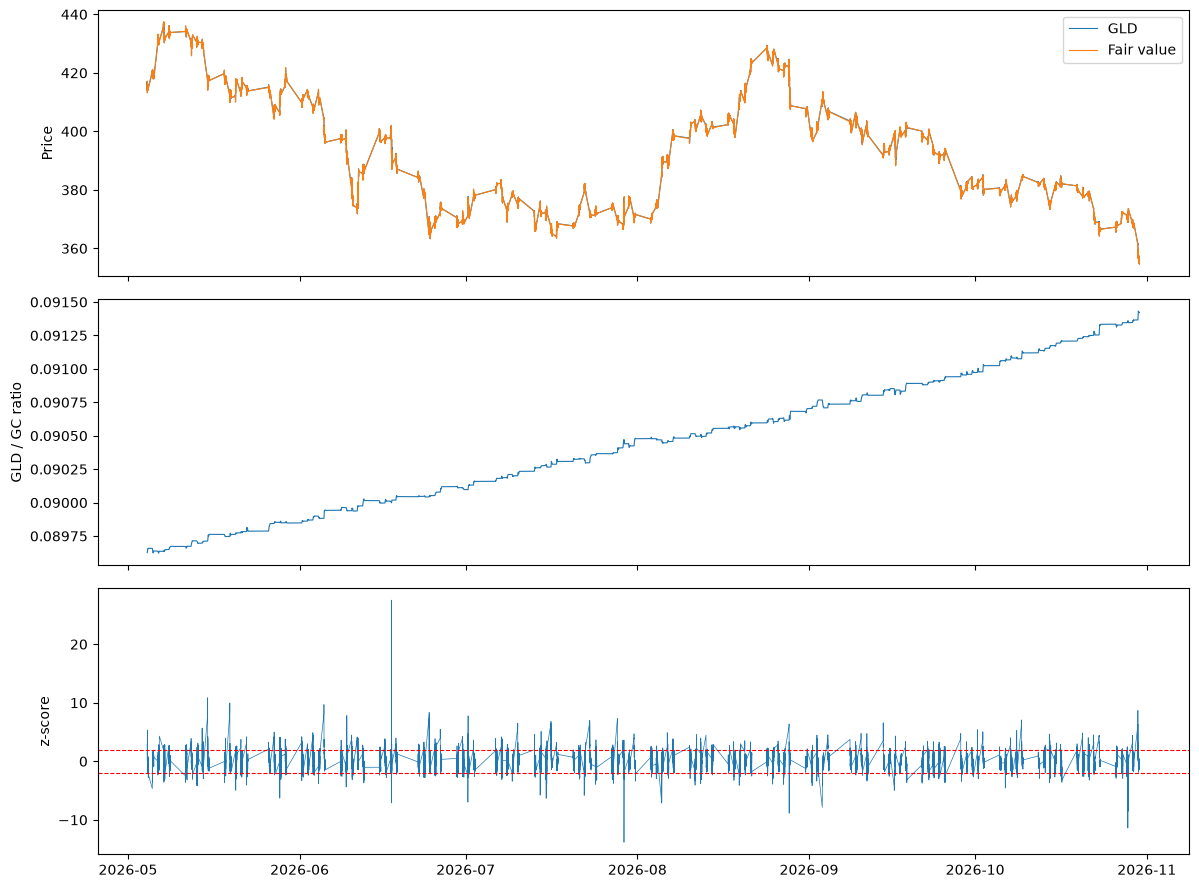

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BARS_PER_DAY = 23400
RATIO_WINDOW = 7200
Z_WINDOW = BARS_PER_DAY

log_ratio = np.log(df["GLD"]) - np.log(df["GC"])
df["ratio"] = np.exp(log_ratio.rolling(RATIO_WINDOW).mean().shift(1))
df["fair"] = df["ratio"] * df["GC"]

df["resid"] = df["GLD"] - df["fair"]

resid_mean = df["resid"].rolling(Z_WINDOW).mean().shift(1)
resid_std = df["resid"].rolling(Z_WINDOW).std().shift(1)

df["z"] = (df["resid"] - resid_mean) / resid_std
df = df.dropna(subset=["z"]).copy()

print(df[["ratio", "resid", "z"]].describe())

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df.index, df["GLD"], label="GLD", lw=0.8)
axes[0].plot(df.index, df["fair"], label="Fair value", lw=0.8)
axes[0].set_ylabel("Price")
axes[0].legend()

axes[1].plot(df.index, df["ratio"], lw=0.8)
axes[1].set_ylabel("GLD / GC ratio")

axes[2].plot(df.index, df["z"], lw=0.5)
for level in (-2, 2):
    axes[2].axhline(level, color="red", ls="--", lw=0.8)
axes[2].set_ylabel("z-score")

plt.tight_layout()
plt.show()

## B. Testing Ideas

### 03 FAIR VALUE SCORECARD

         bias_c  mae_c  rmse_c  p95_abs_c  p99_abs_c  mae_bps  \
1 day     3.063  5.501   7.147     14.713     20.452    1.405   
2 hours   0.930  3.513   4.885     10.157     16.940    0.895   
30 min    0.234  2.121   3.067      5.710     11.223    0.541   
5 min     0.039  1.115   1.606      2.828      4.691    0.284   

         within_half_spread  within_full_spread  
1 day                 0.190               0.364  
2 hours               0.303               0.555  
30 min                0.484               0.759  
5 min                 0.733               0.928   



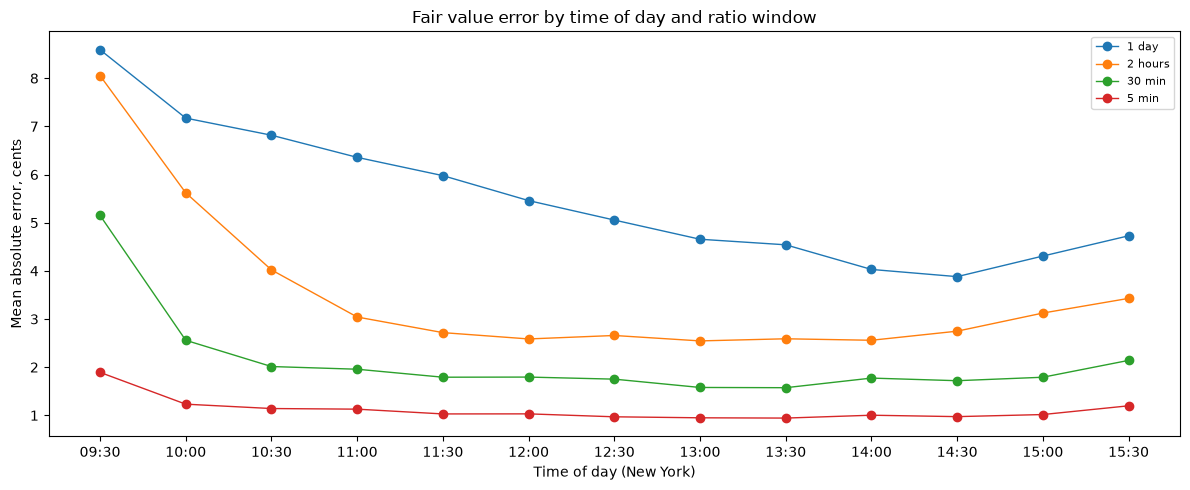

In [4]:
WINDOWS = {"1 day": 23400, "2 hours": 7200, "30 min": 1800, "5 min": 300}

log_ratio = np.log(df["GLD"]) - np.log(df["GC"])
half_spread_c = (df["GLD_ask"] - df["GLD_bid"]) / 2 * 100
day = df.index.normalize()
tod_bucket = (df.index - day).total_seconds() // 1800 * 1800

rows = {}
tod_mae = {}
for name, w in WINDOWS.items():
    fair_w = np.exp(log_ratio.rolling(w, min_periods=w).mean().shift(1)) * df["GC"]
    err = (df["GLD"] - fair_w) * 100
    ok = err.notna()
    e, hs, px = err[ok], half_spread_c[ok], df.loc[ok, "GLD"]
    rows[name] = {
        "bias_c": e.mean(),
        "mae_c": e.abs().mean(),
        "rmse_c": np.sqrt((e ** 2).mean()),
        "p95_abs_c": e.abs().quantile(0.95),
        "p99_abs_c": e.abs().quantile(0.99),
        "mae_bps": (e.abs() / px).mean() * 100,
        "within_half_spread": (e.abs() <= hs).mean(),
        "within_full_spread": (e.abs() <= 2 * hs).mean(),
    }
    tod_mae[name] = e.abs().groupby(tod_bucket[ok]).mean()

score = pd.DataFrame(rows).T
print(score.round(3), "\n")

tod = pd.DataFrame(tod_mae)
tod.index = [f"{int(s // 3600):02d}:{int(s % 3600 // 60):02d}" for s in tod.index]

fig, ax = plt.subplots(figsize=(12, 5))
for name in tod.columns:
    ax.plot(tod.index, tod[name], marker="o", lw=1, label=name)
ax.set_xlabel("Time of day (New York)")
ax.set_ylabel("Mean absolute error, cents")
ax.set_title("Fair value error by time of day and ratio window")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 04 CONTRACT LOAD

In [5]:
CONTRACTS_FILE = DATA / "GC_contracts_mbp1_20260504_20260515.parquet"
DEFS_FILE = DATA / "GC_instrument_definitions_20260501_20261031.parquet"

defs = pd.read_parquet(DEFS_FILE, columns=["ts_recv", "instrument_id", "raw_symbol", "instrument_class", "expiration"])
print(defs["instrument_class"].value_counts(), "\n")
defs = defs.sort_values("ts_recv").drop_duplicates("instrument_id", keep="last")
defs["instrument_id"] = pd.to_numeric(defs["instrument_id"], errors="coerce").astype("Int64")
defs["expiration"] = pd.to_datetime(defs["expiration"], utc=True, errors="coerce")
outrights = defs[
    (defs["instrument_class"] == "F") & defs["raw_symbol"].str.fullmatch(r"GC[A-Z]\d{1,2}")
].dropna(subset=["instrument_id"]).sort_values("expiration")
id_to_sym = dict(zip(outrights["instrument_id"].astype("int64"), outrights["raw_symbol"]))
exp_map = dict(zip(outrights["raw_symbol"], outrights["expiration"]))
print(outrights[["instrument_id", "raw_symbol", "expiration"]].to_string(index=False), "\n")

names = pq.read_schema(CONTRACTS_FILE).names
if "instrument_id" not in names:
    raise KeyError(f"instrument_id missing. Columns: {names}")
cols = ["ts_recv_utc", "instrument_id", "bid_px_00_nano", "ask_px_00_nano"]
eligible = "quote_eligible_on_record" in names
if eligible:
    cols.append("quote_eligible_on_record")

q = pq.read_table(
    CONTRACTS_FILE, columns=cols, filters=[("instrument_id", "in", list(id_to_sym))]
).to_pandas()
if eligible:
    q = q[q["quote_eligible_on_record"]]

q["bid"] = q["bid_px_00_nano"] * 1e-9
q["ask"] = q["ask_px_00_nano"] * 1e-9
q = q[(q["bid"] > 0) & (q["ask"] > q["bid"])]
q["symbol"] = q["instrument_id"].map(id_to_sym)
q["mid"] = (q["bid"] + q["ask"]) / 2
q["spread"] = q["ask"] - q["bid"]

g_start = q["ts_recv_utc"].min().tz_convert(TZ)
g_end = q["ts_recv_utc"].max().tz_convert(TZ)
grid = df.index[(df.index >= g_start) & (df.index <= g_end)]

q_session = q["ts_recv_utc"].dt.tz_convert(TZ)
in_grid_days = q_session.dt.normalize().isin(grid.normalize().unique())
quote_counts = q[in_grid_days].groupby("symbol").size()

q["ts"] = q["ts_recv_utc"].dt.ceil("1s")
q = q.sort_values("ts_recv_utc").drop_duplicates(["symbol", "ts"], keep="last")

def to_grid(values):
    wide = q.pivot(index="ts", columns="symbol", values=values)
    wide.index = wide.index.tz_convert(TZ)
    return wide.reindex(wide.index.union(grid)).ffill().loc[grid]

wide_mid = to_grid("mid")
wide_spread = to_grid("spread")

MIN_ACTIVE = 0.05
coverage = wide_mid.notna().mean()
active = q.loc[q["ts"].dt.tz_convert(TZ).isin(grid)].groupby("symbol").size() / len(grid)
keep = [c for c in wide_mid.columns if coverage.get(c, 0) >= 0.9 and active.get(c, 0) >= MIN_ACTIVE]
order = sorted(keep, key=lambda c: -active[c])
wide_mid = wide_mid[order]
wide_spread = wide_spread[order]

print(f"Grid: {grid[0]} -> {grid[-1]}, {len(grid):,} seconds, {grid.normalize().nunique()} days")
print(pd.DataFrame({
    "expiration": [exp_map[c].date() for c in order],
    "session_quotes": [quote_counts.get(c, 0) for c in order],
    "active_share": [round(active[c], 3) for c in order],
    "coverage": coverage[order].round(3),
}, index=order))

instrument_class
S    181336
F      5434
Name: count, dtype: int64 

 instrument_id raw_symbol                expiration
      42000890       GCJ6 2026-04-28 17:30:00+00:00
      42023114       GCK6 2026-05-27 17:30:00+00:00
         19181       GCM6 2026-06-26 17:30:00+00:00
      42025500       GCN6 2026-07-29 17:30:00+00:00
      42011464       GCQ6 2026-08-27 17:30:00+00:00
      42027353       GCU6 2026-09-28 17:30:00+00:00
      42063221       GCV6 2026-10-28 17:30:00+00:00
      42024734       GCX6 2026-11-25 18:30:00+00:00
         41271       GCZ6 2026-12-29 18:30:00+00:00
      42024763       GCF7 2027-01-27 18:30:00+00:00
      42005245       GCG7 2027-02-24 18:30:00+00:00
      42002254       GCH7 2027-03-29 17:30:00+00:00
      42024857       GCJ7 2027-04-28 17:30:00+00:00
      42025886       GCK7 2027-05-26 17:30:00+00:00
         27459       GCM7 2027-06-28 17:30:00+00:00
      42006015       GCN7 2027-07-28 17:30:00+00:00
      42011758       GCQ7 2027-08-27 17:30:00+0

### 05 HEDGE COMPARISON

      expiration  bad_values  quotes_per_s  spread_eq_c  beta_1s   r2_1s  te_1s_bps  beta_10s  r2_10s  te_10s_bps  beta_60s  r2_60s  te_60s_bps  spread_sd_bps  half_life_min
GCM6  2026-06-26           0         70.07       3.6655   0.9333  0.8614     0.1845    0.9848  0.9686      0.2792    0.9936  0.9902      0.3685         0.8052         6.1482


C:\Users\donna\AppData\Local\Temp\ipykernel_16320\3472493527.py:66: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(fontsize=8)


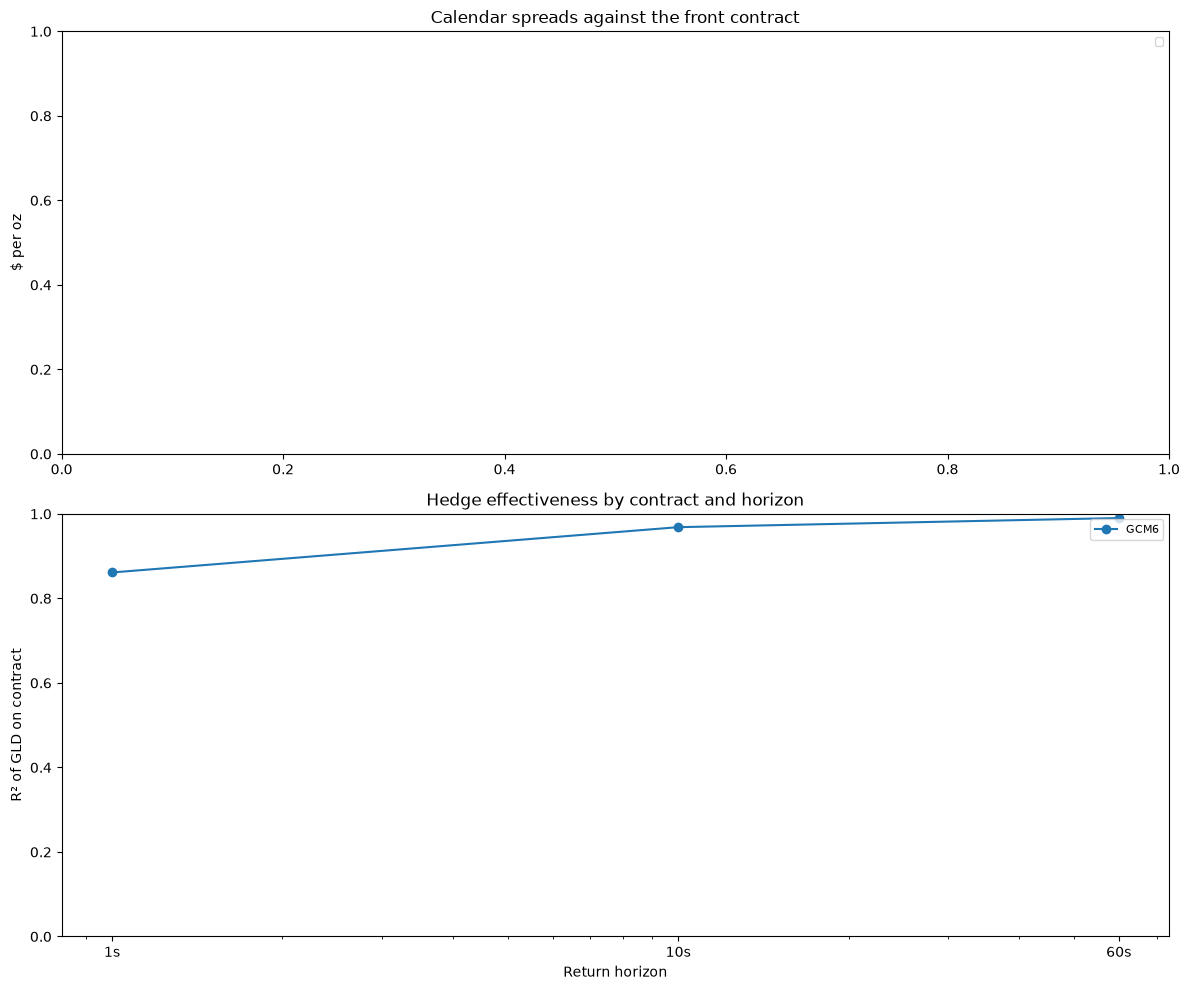

In [6]:
HORIZONS = [1, 10, 60]
AR_STEP = 60
MIN_OBS = 100

g_idx = wide_mid.index
g_day = g_idx.normalize()
g_tod = (g_idx - g_day).total_seconds().to_numpy()
gld_g = df.loc[g_idx, "GLD"]
log_gld = np.log(gld_g)


def slope(x, y):
    xc, yc = x - x.mean(), y - y.mean()
    return (xc * yc).sum() / (xc * xc).sum()


rows = []
for c in wide_mid.columns:
    f = wide_mid[c].where(wide_mid[c] > 0)
    log_f = np.log(f)
    bad = (~np.isfinite(log_f) & wide_mid[c].notna()).sum()
    gld_per_f = (gld_g / f).median()
    row = {
        "expiration": exp_map[c].date(),
        "bad_values": bad,
        "quotes_per_s": quote_counts.get(c, 0) / len(g_idx),
        "spread_eq_c": wide_spread[c].median() * gld_per_f * 100,
    }
    for h in HORIZONS:
        mask = g_tod % h == 0
        r_g = log_gld.groupby(g_day).diff(h)[mask].to_numpy()
        r_f = log_f.groupby(g_day).diff(h)[mask].to_numpy()
        ok = np.isfinite(r_g) & np.isfinite(r_f)
        if ok.sum() < MIN_OBS:
            row[f"beta_{h}s"] = row[f"r2_{h}s"] = row[f"te_{h}s_bps"] = np.nan
            continue
        x, y = r_f[ok], r_g[ok]
        b = slope(x, y)
        row[f"beta_{h}s"] = b
        row[f"r2_{h}s"] = np.corrcoef(x, y)[0, 1] ** 2
        row[f"te_{h}s_bps"] = (y - b * x).std() * 1e4

    ls = (log_gld - log_f) * 1e4
    dev = ls - ls.groupby(g_day).transform("mean")
    nxt = dev.groupby(g_day).shift(-AR_STEP)
    x_ar, y_ar = dev.to_numpy(), nxt.to_numpy()
    m = (g_tod % AR_STEP == 0) & np.isfinite(x_ar) & np.isfinite(y_ar)
    phi = slope(x_ar[m], y_ar[m]) if m.sum() >= MIN_OBS else np.nan
    row["spread_sd_bps"] = np.nanstd(dev.to_numpy())
    row["half_life_min"] = -AR_STEP * np.log(2) / np.log(phi) / 60 if 0 < phi < 1 else np.nan
    rows.append(pd.Series(row, name=c))

hedge = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(hedge.round(4))

front = wide_mid.columns[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for k, c in enumerate(wide_mid.columns[1:], start=1):
    cal = wide_mid[c] - wide_mid[front]
    for i, (_, seg) in enumerate(cal.groupby(g_day)):
        axes[0].plot(seg.index, seg, color=f"C{k}", lw=0.6, label=f"{c} - {front}" if i == 0 else None)
axes[0].set_ylabel("$ per oz")
axes[0].set_title("Calendar spreads against the front contract")
axes[0].legend(fontsize=8)

for k, c in enumerate(wide_mid.columns):
    axes[1].plot(HORIZONS, [hedge.loc[c, f"r2_{h}s"] for h in HORIZONS], marker="o", color=f"C{k}", label=c)
axes[1].set_xscale("log")
axes[1].set_xticks(HORIZONS)
axes[1].set_xticklabels([f"{h}s" for h in HORIZONS])
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Return horizon")
axes[1].set_ylabel("R² of GLD on contract")
axes[1].set_title("Hedge effectiveness by contract and horizon")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 06 LAG CHECK

In [7]:
LAGS = range(-3, 4)


def xcorr(a, b, d):
    ra = np.log(a).groupby(d).diff()
    rb = np.log(b).groupby(d).diff()
    return pd.Series({k: ra.corr(rb.groupby(d).shift(k)) for k in LAGS})


main_day = df.index.normalize()
main_xc = xcorr(df["GLD"], df["GC"], main_day)

tick_front = wide_mid.columns[0]
tick_xc = xcorr(gld_g, wide_mid[tick_front], g_day)

table = pd.DataFrame({
    "1s files: GLD vs GC": main_xc,
    f"tick file: GLD vs {tick_front}": tick_xc,
})
table.index.name = "k (GC lag, s)"
print(table.round(4))

               1s files: GLD vs GC  tick file: GLD vs GCM6
k (GC lag, s)                                             
-3                          0.0016                  0.0056
-2                          0.0034                  0.0093
-1                          0.0175                  0.0138
0                           0.9443                  0.9281
1                           0.0312                  0.0349
2                           0.0086                  0.0191
3                           0.0060                  0.0125


### 07 EDGE BY GAP SIZE

In [8]:
HORIZONS = [300, 1800, 7200]
STEP = 5
GAP_BINS = [0, 0.01, 0.02, 0.03, 0.05, 0.08, np.inf]

day = df.index.normalize()


def shift_in_day(series, n):
    return series.groupby(day).shift(n)


dev = df["resid"] - resid_mean.reindex(df.index)
gld_spread = df["GLD_ask"] - df["GLD_bid"]

adjust_rows = []
for h in HORIZONS:
    d_gld = shift_in_day(df["GLD"], -(h + 1)) - shift_in_day(df["GLD"], -1)
    d_fair = df["ratio"] * (shift_in_day(df["GC"], -(h + 1)) - shift_in_day(df["GC"], -1))
    cost_h = (shift_in_day(gld_spread, -1) + shift_in_day(gld_spread, -(h + 1))) / 2

    gap_data = pd.DataFrame({"dev": dev, "d_gld": d_gld, "d_fair": d_fair, "cost": cost_h}).iloc[::STEP].dropna()

    a_gld = np.polyfit(gap_data["dev"], gap_data["d_gld"], 1)[0]
    a_fair = np.polyfit(gap_data["dev"], gap_data["d_fair"], 1)[0]
    adjust_rows.append({
        "horizon_s": h,
        "alpha_gld": a_gld,
        "alpha_fair": a_fair,
        "gap_closed": a_fair - a_gld,
        "gld_share": -a_gld / (a_fair - a_gld),
    })

    side = np.sign(gap_data["dev"])
    gap_data["gross"] = -side * gap_data["d_gld"]
    gap_data["net"] = gap_data["gross"] - gap_data["cost"]
    gap_data["gap_bin"] = pd.cut(gap_data["dev"].abs(), GAP_BINS)

    gap_table = gap_data.groupby("gap_bin", observed=True).agg(
        n=("net", "size"),
        gross=("gross", "mean"),
        cost=("cost", "mean"),
        net=("net", "mean"),
        hit=("net", lambda x: (x > 0).mean()),
    )
    print(f"Horizon {h}s")
    print(gap_table.round(4), "\n")

print(pd.DataFrame(adjust_rows).set_index("horizon_s").round(4))

Horizon 300s
                   n   gross    cost     net     hit
gap_bin                                             
(0.0, 0.01]   118520 -0.0015  0.0307 -0.0321  0.4451
(0.01, 0.02]  109178 -0.0020  0.0307 -0.0328  0.4427
(0.02, 0.03]   92403 -0.0006  0.0309 -0.0315  0.4455
(0.03, 0.05]  128351 -0.0044  0.0313 -0.0356  0.4425
(0.05, 0.08]   85713 -0.0101  0.0330 -0.0430  0.4403
(0.08, inf]    46515 -0.0002  0.0390 -0.0392  0.4616 

Horizon 1800s
                   n   gross    cost     net     hit
gap_bin                                             
(0.0, 0.01]   111505 -0.0012  0.0307 -0.0319  0.4786
(0.01, 0.02]  102349 -0.0174  0.0308 -0.0482  0.4736
(0.02, 0.03]   86030 -0.0178  0.0309 -0.0487  0.4741
(0.03, 0.05]  118683 -0.0172  0.0313 -0.0485  0.4808
(0.05, 0.08]   79518 -0.0324  0.0329 -0.0653  0.4617
(0.08, inf]    44795  0.0949  0.0385  0.0564  0.5133 

Horizon 7200s
                  n   gross    cost     net     hit
gap_bin                                            
(0.

### 08 SPREAD PDF

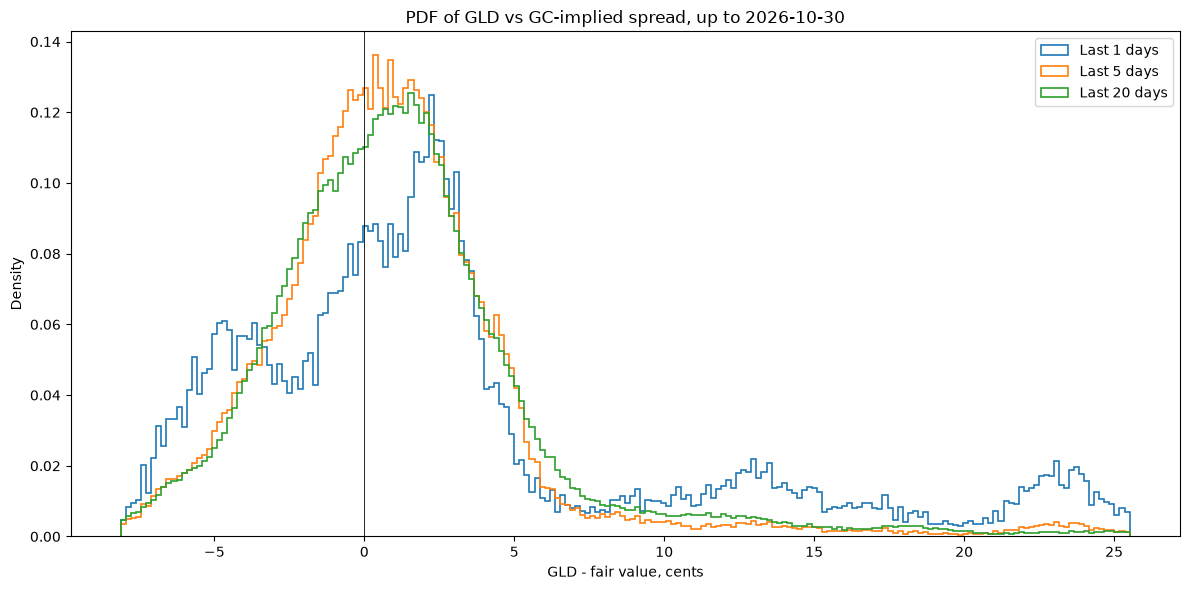

       days_1  days_5  days_20
0.01    -7.39   -7.18    -7.33
0.025   -6.70   -6.11    -6.15
0.05    -5.90   -4.97    -4.92
0.25    -1.83   -1.48    -1.54
0.5      1.57    0.62     0.80
0.75     4.66    2.71     3.02
0.95    23.34    7.88     9.64
0.975   25.42   14.45    14.18
0.99    27.31   23.34    20.24
mean     3.50    1.06     1.26
std      8.35    4.77     4.78


In [9]:
END_DAY = "2026-10-30"
HORIZONS_DAYS = [1, 5, 20]
BINS = 200

day = df.index.normalize()
days = day.unique()
end = pd.Timestamp(END_DAY, tz=TZ)
past_days = days[days <= end]

spread_c = df["resid"] * 100

samples = {}
for n in HORIZONS_DAYS:
    window_days = past_days[-n:]
    samples[n] = spread_c[day.isin(window_days)].dropna()

all_vals = pd.concat(samples.values())
lo, hi = all_vals.quantile([0.005, 0.995])
edges = np.linspace(lo, hi, BINS + 1)

fig, ax = plt.subplots(figsize=(12, 6))
for n, s in samples.items():
    ax.hist(s[(s >= lo) & (s <= hi)], bins=edges, density=True, histtype="step", lw=1.2, label=f"Last {n} days")
ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("GLD - fair value, cents")
ax.set_ylabel("Density")
ax.set_title(f"PDF of GLD vs GC-implied spread, up to {END_DAY}")
ax.legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    n: s.quantile([0.01, 0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975, 0.99]).round(2)
    for n, s in samples.items()
}).add_prefix("days_")
summary.loc["mean"] = [s.mean().round(2) for s in samples.values()]
summary.loc["std"] = [s.std().round(2) for s in samples.values()]
print(summary)

### 09 ROLLING QUANTILE ESTIMATOR

In [10]:
LOOKBACK_S = 3600
Q_LO = 0.025
Q_HI = 0.975

day = df.index.normalize()
df["spread_c"] = df["resid"] * 100

past = df["spread_c"].groupby(day).shift(1)
roll = past.groupby(day).rolling(LOOKBACK_S, min_periods=LOOKBACK_S)

df["q_lo"] = roll.quantile(Q_LO).droplevel(0)
df["q_med"] = roll.median().droplevel(0)
df["q_hi"] = roll.quantile(Q_HI).droplevel(0)
df["u"] = (
    df["spread_c"].groupby(day)
    .rolling(LOOKBACK_S + 1, min_periods=LOOKBACK_S + 1)
    .rank(pct=True)
    .droplevel(0)
)
df["signal"] = np.where(df["u"].isna(), np.nan, np.select([df["u"] >= Q_HI, df["u"] <= Q_LO], [-1, 1], 0))

valid = df["u"].notna()
band = (df["q_hi"] - df["q_lo"])[valid]
print(f"Share above q{Q_HI}: {(df.loc[valid, 'u'] >= Q_HI).mean():.4f}  (target {1 - Q_HI:.4f})")
print(f"Share below q{Q_LO}: {(df.loc[valid, 'u'] <= Q_LO).mean():.4f}  (target {Q_LO:.4f})")
print(f"Band width q{Q_LO} to q{Q_HI}: median {band.median():.2f} cents, 10th pct {band.quantile(0.1):.2f}, 90th pct {band.quantile(0.9):.2f}")

Share above q0.975: 0.0618  (target 0.0250)
Share below q0.025: 0.0725  (target 0.0250)
Band width q0.025 to q0.975: median 7.43 cents, 10th pct 4.91, 90th pct 12.30


### 10 ROLLING QUANTILE PLOTS

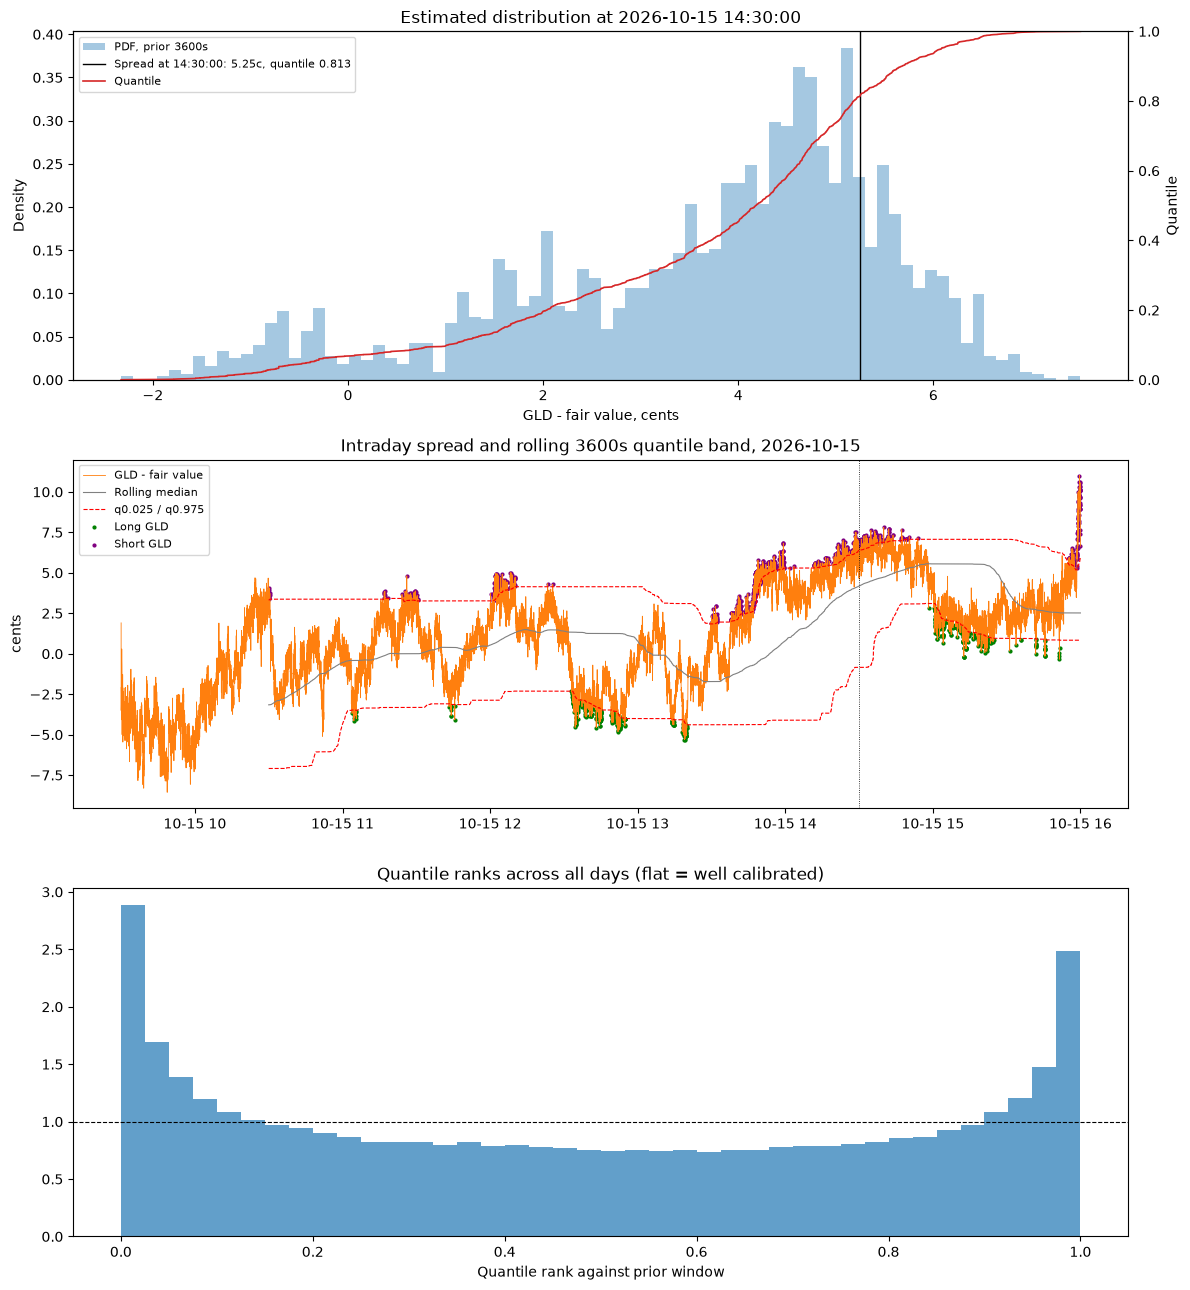

In [11]:
DAY = "2026-10-15"
TIME = "2026-10-15 14:30:00"

d = pd.Timestamp(DAY, tz=TZ)
t = pd.Timestamp(TIME, tz=TZ)

est = np.sort(
    df.loc[(df.index >= t - pd.Timedelta(seconds=LOOKBACK_S)) & (df.index < t), "spread_c"].dropna().to_numpy()
)
now = df.loc[t, "spread_c"]
now_u = np.searchsorted(est, now) / len(est)

fig, axes = plt.subplots(3, 1, figsize=(12, 13))

ax1 = axes[0]
ax1.hist(est, bins=80, density=True, alpha=0.4, color="C0", label=f"PDF, prior {LOOKBACK_S}s")
ax1.axvline(now, color="black", lw=1, label=f"Spread at {TIME[-8:]}: {now:.2f}c, quantile {now_u:.3f}")
ax1.set_xlabel("GLD - fair value, cents")
ax1.set_ylabel("Density")
ax2 = ax1.twinx()
ax2.plot(est, np.arange(1, len(est) + 1) / len(est), color="C3", lw=1.2, label="Quantile")
ax2.set_ylim(0, 1)
ax2.set_ylabel("Quantile")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax1.set_title(f"Estimated distribution at {TIME}")

one = df.loc[day == d]
long_mask = one["signal"] == 1
short_mask = one["signal"] == -1
axes[1].plot(one.index, one["spread_c"], lw=0.6, color="C1", label="GLD - fair value")
axes[1].plot(one.index, one["q_med"], lw=0.8, color="grey", label="Rolling median")
axes[1].plot(one.index, one["q_lo"], lw=0.8, color="red", ls="--", label=f"q{Q_LO} / q{Q_HI}")
axes[1].plot(one.index, one["q_hi"], lw=0.8, color="red", ls="--")
axes[1].scatter(one.index[long_mask], one.loc[long_mask, "spread_c"], s=4, color="green", label="Long GLD")
axes[1].scatter(one.index[short_mask], one.loc[short_mask, "spread_c"], s=4, color="purple", label="Short GLD")
axes[1].axvline(t, color="black", lw=0.6, ls=":")
axes[1].set_ylabel("cents")
axes[1].set_title(f"Intraday spread and rolling {LOOKBACK_S}s quantile band, {DAY}")
axes[1].legend(fontsize=8)

axes[2].hist(df["u"].dropna().iloc[::5], bins=40, density=True, color="C0", alpha=0.7)
axes[2].axhline(1, color="black", lw=0.8, ls="--")
axes[2].set_xlabel("Quantile rank against prior window")
axes[2].set_title("Quantile ranks across all days (flat = well calibrated)")

plt.tight_layout()
plt.show()

## C. Backtest

### 11 VOL-ADJUSTED ESTIMATOR

In [12]:
HL_MEAN = 1800
HL_VOL = 600
Z_LOOKBACK_DAYS = 20
SAMPLE = 5
Q_LO = 0.025
Q_HI = 0.975

day = df.index.normalize()
days = day.unique()
df["spread_c"] = df["resid"] * 100

def ewm_in_day(series, halflife):
    return series.groupby(day).transform(lambda s: s.ewm(halflife=halflife, min_periods=halflife).mean())

df["loc_c"] = ewm_in_day(df["spread_c"], HL_MEAN).groupby(day).shift(1)
dev_c = df["spread_c"] - df["loc_c"]
df["vol_c"] = np.sqrt(ewm_in_day(dev_c ** 2, HL_VOL)).groupby(day).shift(1)
df["z_va"] = dev_c / df["vol_c"]

z = df["z_va"].to_numpy()
day_pos = {d: np.flatnonzero(day == d) for d in days}

u_va = np.full(len(df), np.nan)
z_hist_by_day = {}
zq_rows = {}
for i, d in enumerate(days):
    if i < Z_LOOKBACK_DAYS:
        continue
    hist = np.concatenate([z[day_pos[x]][::SAMPLE] for x in days[i - Z_LOOKBACK_DAYS:i]])
    hist = np.sort(hist[np.isfinite(hist)])
    z_hist_by_day[d] = hist
    zq_rows[d] = np.quantile(hist, [Q_LO, 0.5, Q_HI])
    pos = day_pos[d]
    zz = z[pos]
    u_va[pos] = np.where(np.isfinite(zz), np.searchsorted(hist, zz) / len(hist), np.nan)

zq = pd.DataFrame(zq_rows, index=["z_lo", "z_med", "z_hi"]).T
zq_bar = zq.reindex(day).to_numpy()

df["u_va"] = u_va
df["q_lo_va"] = df["loc_c"] + df["vol_c"] * zq_bar[:, 0]
df["q_med_va"] = df["loc_c"] + df["vol_c"] * zq_bar[:, 1]
df["q_hi_va"] = df["loc_c"] + df["vol_c"] * zq_bar[:, 2]
df["signal_va"] = np.where(df["u_va"].isna(), np.nan, np.select([df["u_va"] >= Q_HI, df["u_va"] <= Q_LO], [-1, 1], 0))

valid = df["u_va"].notna()
band = (df["q_hi_va"] - df["q_lo_va"])[valid]
print(zq.describe().round(3), "\n")
print(f"Normal reference: z_lo {-1.96:.3f}, z_hi {1.96:.3f}\n")
print(f"Share above q{Q_HI}: {(df.loc[valid, 'u_va'] >= Q_HI).mean():.4f}  (target {1 - Q_HI:.4f})")
print(f"Share below q{Q_LO}: {(df.loc[valid, 'u_va'] <= Q_LO).mean():.4f}  (target {Q_LO:.4f})")
print(f"Band width: median {band.median():.2f} cents, 10th pct {band.quantile(0.1):.2f}, 90th pct {band.quantile(0.9):.2f}")

          z_lo    z_med     z_hi
count  106.000  106.000  106.000
mean    -1.829   -0.151    1.740
std      0.051    0.102    0.044
min     -1.925   -0.348    1.646
25%     -1.869   -0.242    1.708
50%     -1.823   -0.154    1.752
75%     -1.787   -0.077    1.776
max     -1.735    0.079    1.806 

Normal reference: z_lo -1.960, z_hi 1.960

Share above q0.975: 0.0250  (target 0.0250)
Share below q0.025: 0.0245  (target 0.0250)
Band width: median 8.58 cents, 10th pct 5.12, 90th pct 17.03


### 12 VOL-ADJUSTED PLOTS

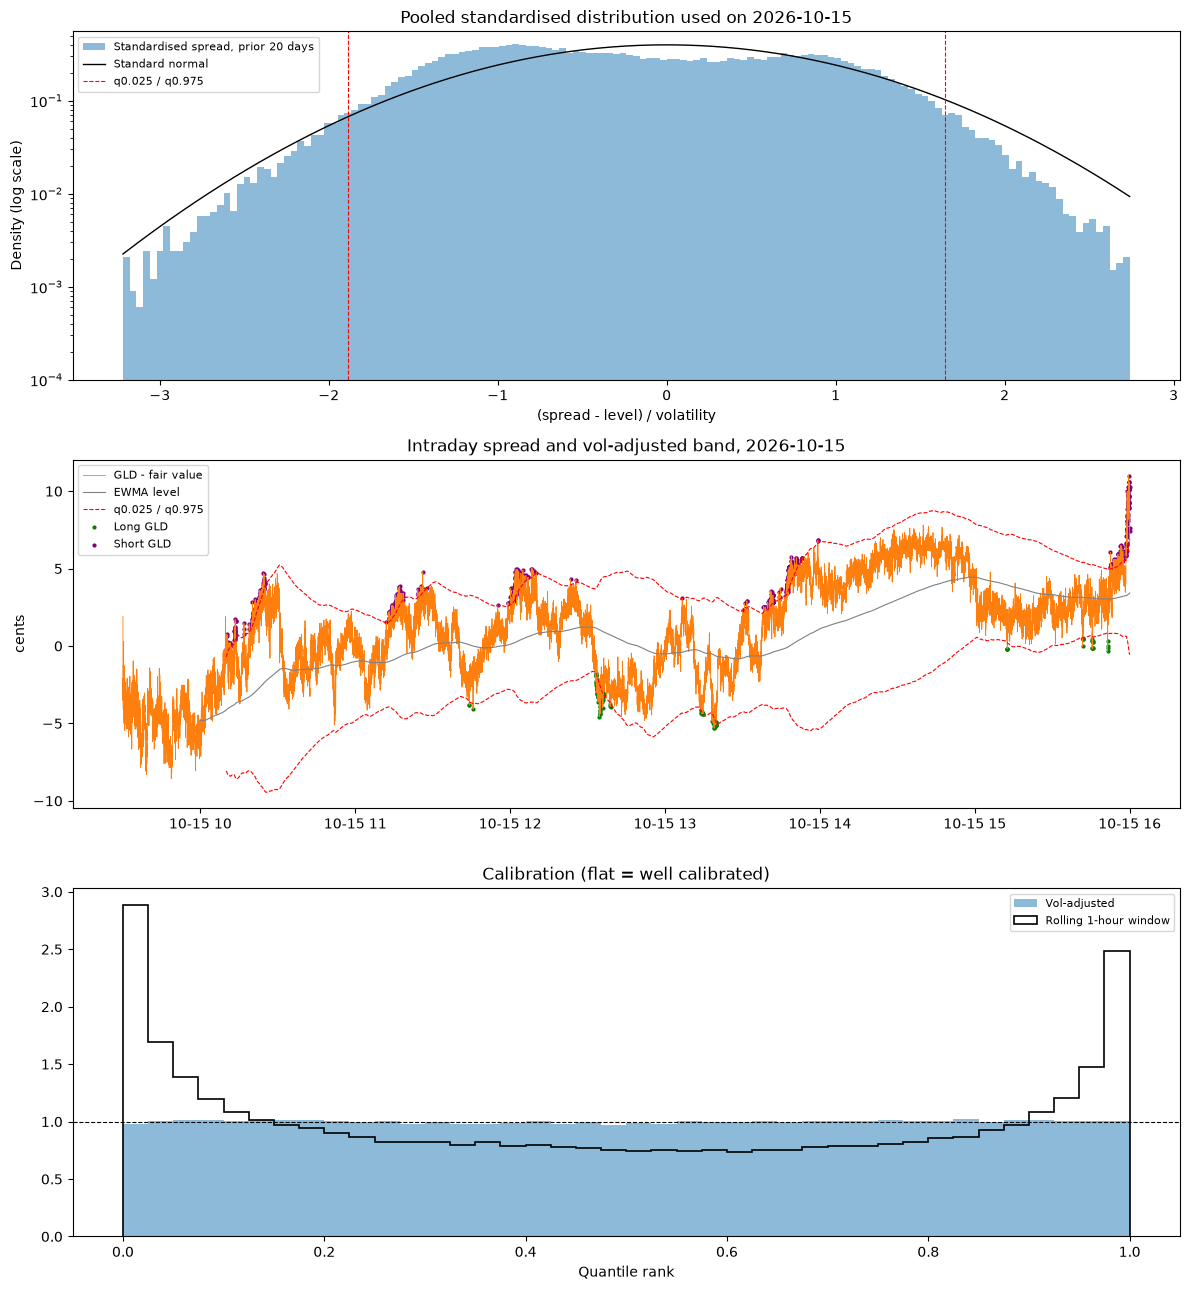

In [13]:
DAY = "2026-10-15"

d = pd.Timestamp(DAY, tz=TZ)
hist = z_hist_by_day[d]
lo, hi = np.quantile(hist, [0.0005, 0.9995])
x = np.linspace(lo, hi, 400)

fig, axes = plt.subplots(3, 1, figsize=(12, 13))

axes[0].hist(hist[(hist >= lo) & (hist <= hi)], bins=150, density=True, alpha=0.5, color="C0", label=f"Standardised spread, prior {Z_LOOKBACK_DAYS} days")
axes[0].plot(x, np.exp(-x ** 2 / 2) / np.sqrt(2 * np.pi), color="black", lw=1, label="Standard normal")
axes[0].axvline(zq.loc[d, "z_lo"], color="red", ls="--", lw=0.8, label=f"q{Q_LO} / q{Q_HI}")
axes[0].axvline(zq.loc[d, "z_hi"], color="red", ls="--", lw=0.8)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-4, None)
axes[0].set_xlabel("(spread - level) / volatility")
axes[0].set_ylabel("Density (log scale)")
axes[0].set_title(f"Pooled standardised distribution used on {DAY}")
axes[0].legend(fontsize=8)

one = df.loc[day == d]
long_mask = one["signal_va"] == 1
short_mask = one["signal_va"] == -1
axes[1].plot(one.index, one["spread_c"], lw=0.6, color="C1", label="GLD - fair value")
axes[1].plot(one.index, one["loc_c"], lw=0.8, color="grey", label="EWMA level")
axes[1].plot(one.index, one["q_lo_va"], lw=0.8, color="red", ls="--", label=f"q{Q_LO} / q{Q_HI}")
axes[1].plot(one.index, one["q_hi_va"], lw=0.8, color="red", ls="--")
axes[1].scatter(one.index[long_mask], one.loc[long_mask, "spread_c"], s=4, color="green", label="Long GLD")
axes[1].scatter(one.index[short_mask], one.loc[short_mask, "spread_c"], s=4, color="purple", label="Short GLD")
axes[1].set_ylabel("cents")
axes[1].set_title(f"Intraday spread and vol-adjusted band, {DAY}")
axes[1].legend(fontsize=8)

bins = np.linspace(0, 1, 41)
axes[2].hist(df["u_va"].dropna().iloc[::5], bins=bins, density=True, histtype="stepfilled", alpha=0.5, color="C0", label="Vol-adjusted")
if "u" in df:
    axes[2].hist(df["u"].dropna().iloc[::5], bins=bins, density=True, histtype="step", lw=1.2, color="black", label="Rolling 1-hour window")
axes[2].axhline(1, color="black", lw=0.8, ls="--")
axes[2].set_xlabel("Quantile rank")
axes[2].set_title("Calibration (flat = well calibrated)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 13 BACKTEST ENGINE

In [14]:
try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        if args and callable(args[0]):
            return args[0]
        return lambda f: f

BASE = {
    "gap_rule": "fixed",
    "min_gap_c": 8.0,
    "cost_mult": 2.0,
    "cost_basis": "own",
    "max_hold": 900,
    "stop_sigma": 3.0,
    "exit_on_target": True,
    "last_entry": "15:30:00",
    "exit_at": "15:55:00",
    "spread_max_c": 5.0,
}
MODES = ["touch", "reentry"]
VARIANTS = ["GLD-only", "hedged"]
REASONS = np.array(["close", "target", "stop", "time"])

bt_idx = df.index
bt_day = bt_idx.normalize()

BT = {
    "s": df["spread_c"].to_numpy(float),
    "lvl": df["loc_c"].to_numpy(float),
    "lo": df["q_lo_va"].to_numpy(float),
    "hi": df["q_hi_va"].to_numpy(float),
    "vol": df["vol_c"].to_numpy(float),
    "bid": df["GLD_bid"].to_numpy(float),
    "ask": df["GLD_ask"].to_numpy(float),
    "mid": df["GLD"].to_numpy(float),
    "gc_mid": df["GC_raw"].to_numpy(float),
    "day_id": pd.factorize(bt_day)[0].astype(np.int64),
    "tod": (bt_idx - bt_day).total_seconds().to_numpy(float),
}
gc_half = df["GC_spread"].to_numpy(float) / 2
BT["gc_bid"] = BT["gc_mid"] - gc_half
BT["gc_ask"] = BT["gc_mid"] + gc_half
BT["gld_spread_c"] = (BT["ask"] - BT["bid"]) * 100
BT["gc_spread_c"] = df["ratio"].to_numpy(float) * df["GC_spread"].to_numpy(float) * 100
BT["ready"] = np.isfinite(BT["lo"]) & np.isfinite(BT["hi"]) & np.isfinite(BT["lvl"]) & np.isfinite(BT["vol"])

valid_days = pd.Index(bt_day[BT["ready"]]).unique()


@njit(cache=True)
def _core(s, lvl, lo, hi, vol, ready, can_enter, gap_ok, day_id, tod,
          exit_at_s, max_hold, stop_sigma, reentry, use_target):
    n = s.shape[0]
    ent = np.empty(n, np.int64)
    ext = np.empty(n, np.int64)
    rsn = np.empty(n, np.int64)
    sid = np.empty(n, np.int64)
    k = 0
    pos = 0
    armed = 0
    e_i = 0
    e_s = 0.0
    e_vol = 0.0
    for i in range(1, n - 1):
        j = i + 1
        if day_id[j] != day_id[i]:
            armed = 0
            continue
        if pos != 0:
            r = -1
            if tod[i] >= exit_at_s:
                r = 0
            elif use_target and ((pos == -1 and s[i] <= lvl[i]) or (pos == 1 and s[i] >= lvl[i])):
                r = 1
            elif pos * (s[i] - e_s) <= -stop_sigma * e_vol:
                r = 2
            elif i - e_i >= max_hold:
                r = 3
            if r >= 0:
                ent[k] = e_i
                ext[k] = j
                rsn[k] = r
                sid[k] = pos
                k += 1
                pos = 0
            continue
        if not ready[i]:
            armed = 0
            continue
        sig = 0
        if not reentry:
            if s[i] >= hi[i] and s[i - 1] < hi[i - 1]:
                sig = -1
            elif s[i] <= lo[i] and s[i - 1] > lo[i - 1]:
                sig = 1
        else:
            if s[i] >= hi[i]:
                armed = -1
            elif s[i] <= lo[i]:
                armed = 1
            elif (armed == -1 and s[i] <= lvl[i]) or (armed == 1 and s[i] >= lvl[i]):
                armed = 0
            elif armed != 0:
                sig = armed
                armed = 0
        if sig != 0 and can_enter[i] and gap_ok[i]:
            pos = sig
            e_i = i
            e_s = s[i]
            e_vol = vol[i]
    return ent[:k], ext[:k], rsn[:k], sid[:k]


def build_trades(ent, ext, rsn, sid, hedged):
    fi = ent + 1
    side = sid.astype(float)
    bid, ask, mid = BT["bid"], BT["ask"], BT["mid"]
    gb, ga, gm = BT["gc_bid"], BT["gc_ask"], BT["gc_mid"]

    e_px = np.where(side > 0, ask[fi], bid[fi])
    x_px = np.where(side > 0, bid[ext], ask[ext])
    gld_gross = side * (mid[ext] - mid[fi]) * 100
    gld_net = side * (x_px - e_px) * 100

    gc_units = -side * mid[fi] / gm[fi]
    e_gc = np.where(gc_units > 0, ga[fi], gb[fi])
    x_gc = np.where(gc_units > 0, gb[ext], ga[ext])
    gc_gross = gc_units * (gm[ext] - gm[fi]) * 100
    gc_net = gc_units * (x_gc - e_gc) * 100

    gross = gld_gross + (gc_gross if hedged else 0.0)
    net = gld_net + (gc_net if hedged else 0.0)

    return pd.DataFrame({
        "day": bt_day[ent],
        "entry_time": bt_idx[fi],
        "exit_time": bt_idx[ext],
        "side": sid,
        "hold_s": ext - fi,
        "reason": REASONS[rsn],
        "entry_gap_c": BT["s"][ent] - BT["lvl"][ent],
        "gld_entry_px": e_px,
        "gld_exit_px": x_px,
        "gc_units": gc_units,
        "gc_entry_px": e_gc,
        "gc_exit_px": x_gc,
        "spread_capture_c": side * (BT["s"][ext] - BT["s"][fi]),
        "gld_gross_c": gld_gross,
        "gld_net_c": gld_net,
        "gc_gross_c": gc_gross,
        "gc_net_c": gc_net,
        "gross_mid_c": gross,
        "cost_c": gross - net,
        "net_c": net,
    })


def run_backtest(mode, variant, **overrides):
    p = {**BASE, **overrides}
    hedged = variant == "hedged"
    last_entry_s = pd.Timedelta(p["last_entry"]).total_seconds()
    exit_at_s = pd.Timedelta(p["exit_at"]).total_seconds()
    can_enter = BT["ready"] & (BT["tod"] < last_entry_s) & (BT["gld_spread_c"] <= p["spread_max_c"])

    if p["gap_rule"] == "fixed":
        thr = np.full(len(BT["s"]), float(p["min_gap_c"]))
    else:
        own = p["cost_basis"] == "own" and not hedged
        basis = BT["gld_spread_c"] if own else BT["gld_spread_c"] + BT["gc_spread_c"]
        thr = p["cost_mult"] * basis
    with np.errstate(invalid="ignore"):
        gap_ok = np.abs(BT["s"] - BT["lvl"]) >= thr

    ent, ext, rsn, sid = _core(
        BT["s"], BT["lvl"], BT["lo"], BT["hi"], BT["vol"], BT["ready"], can_enter, gap_ok,
        BT["day_id"], BT["tod"], float(exit_at_s), int(p["max_hold"]), float(p["stop_sigma"]),
        mode == "reentry", bool(p["exit_on_target"]),
    )
    return build_trades(ent, ext, rsn, sid, hedged)


def summarise(tr):
    keys = [
        "trades", "trades_per_day", "hit_rate", "avg_spread_capture_c", "avg_gross_mid_c", "avg_cost_c",
        "avg_net_c", "t_stat", "avg_hold_s", "total_net_c", "daily_sharpe_ann", "max_drawdown_c",
    ]
    if len(tr) < 2:
        out = pd.Series(np.nan, index=keys)
        out["trades"] = len(tr)
        return out
    net = tr["net_c"]
    daily = net.groupby(tr["day"]).sum().reindex(valid_days, fill_value=0.0)
    cum = daily.cumsum()
    return pd.Series({
        "trades": len(tr),
        "trades_per_day": len(tr) / len(valid_days),
        "hit_rate": (net > 0).mean(),
        "avg_spread_capture_c": tr["spread_capture_c"].mean(),
        "avg_gross_mid_c": tr["gross_mid_c"].mean(),
        "avg_cost_c": tr["cost_c"].mean(),
        "avg_net_c": net.mean(),
        "t_stat": net.mean() / (net.std(ddof=1) / np.sqrt(len(net))),
        "avg_hold_s": tr["hold_s"].mean(),
        "total_net_c": net.sum(),
        "daily_sharpe_ann": daily.mean() / daily.std() * np.sqrt(252) if daily.std() > 0 else np.nan,
        "max_drawdown_c": (cum - cum.cummax()).min(),
    })


print(f"Backtest arrays ready: {len(BT['s']):,} bars, {len(valid_days)} tradable days")

Backtest arrays ready: 2,941,200 bars, 106 tradable days


### 14 BACKTEST RUN

In [15]:
results = {f"{m} {v}": run_backtest(m, v) for m in MODES for v in VARIANTS}

summary = pd.DataFrame({name: summarise(tr) for name, tr in results.items()})
pd.set_option("display.width", 200)
print(f"Settings: {BASE}\n")
print(summary.round(3), "\n")

for name, tr in results.items():
    print(f"{name}: exits by reason")
    print(tr.groupby("reason")[["spread_capture_c", "net_c"]].agg(["count", "mean"]).round(3), "\n")

Settings: {'gap_rule': 'fixed', 'min_gap_c': 8.0, 'cost_mult': 2.0, 'cost_basis': 'own', 'max_hold': 900, 'stop_sigma': 3.0, 'exit_on_target': True, 'last_entry': '15:30:00', 'exit_at': '15:55:00', 'spread_max_c': 5.0}

                      touch GLD-only  touch hedged  reentry GLD-only  reentry hedged
trades                       154.000       154.000            69.000          69.000
trades_per_day                 1.453         1.453             0.651           0.651
hit_rate                       0.461         0.136             0.536           0.188
avg_spread_capture_c           1.928         1.928             2.071           2.071
avg_gross_mid_c                0.539         2.035            14.739           2.166
avg_cost_c                     3.565         6.704             3.623           6.935
avg_net_c                     -3.026        -4.668            11.116          -4.769
t_stat                        -0.520       -11.885             1.215          -7.992
avg_hold_s     

### 15 BACKTEST PLOTS

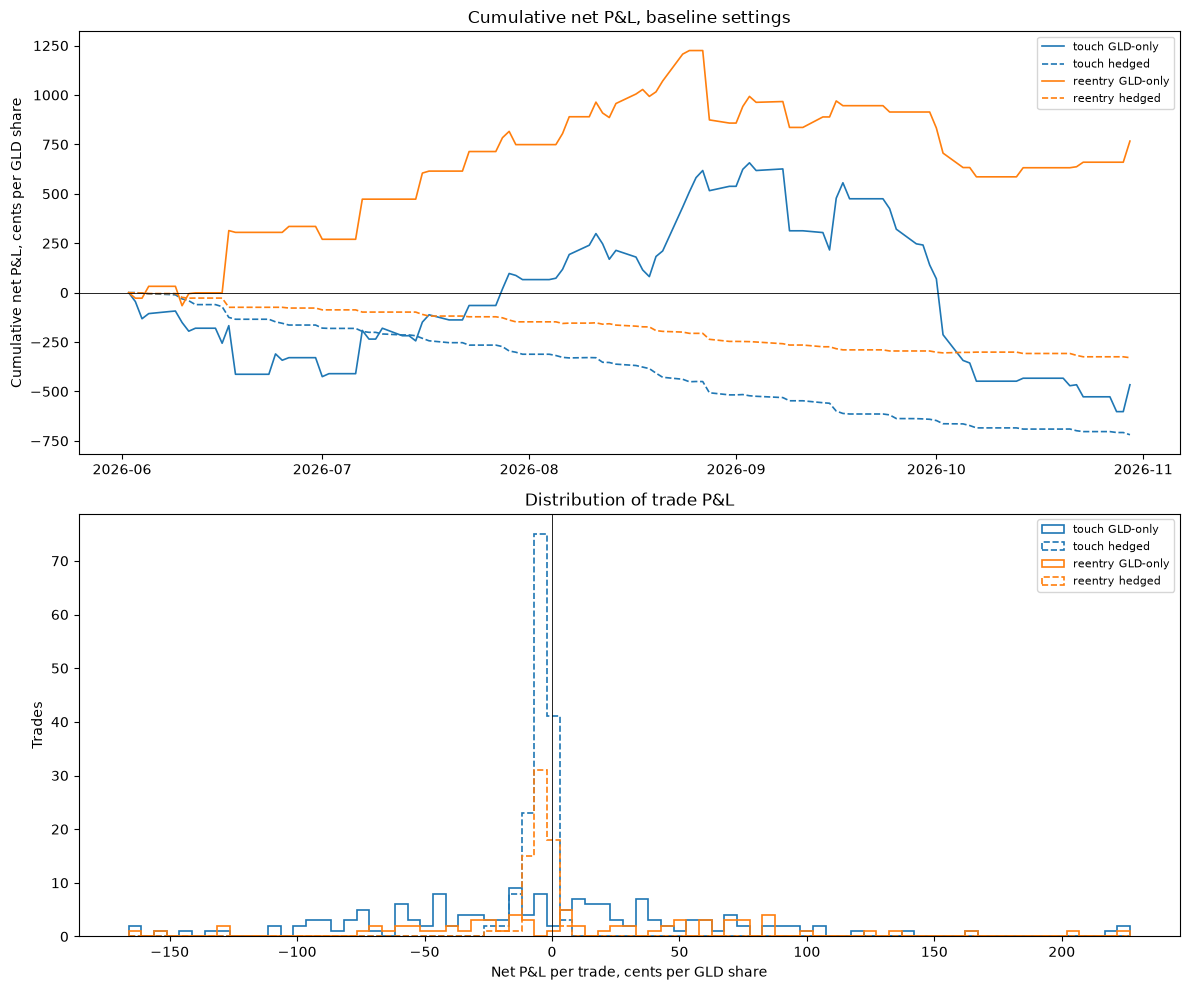

In [16]:
style = {"GLD-only": "-", "hedged": "--"}

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for name, tr in results.items():
    m, v = name.split(" ", 1)
    color = f"C{MODES.index(m)}"
    daily_net = tr.groupby("day")["net_c"].sum().reindex(valid_days, fill_value=0.0)
    axes[0].plot(valid_days, daily_net.cumsum(), color=color, lw=1.2, ls=style[v], label=name)
axes[0].axhline(0, color="black", lw=0.6)
axes[0].set_ylabel("Cumulative net P&L, cents per GLD share")
axes[0].set_title("Cumulative net P&L, baseline settings")
axes[0].legend(fontsize=8)

all_net = pd.concat([tr["net_c"] for tr in results.values()])
lo_b, hi_b = all_net.quantile([0.005, 0.995])
bins = np.linspace(lo_b, hi_b, 80)
for name, tr in results.items():
    m, v = name.split(" ", 1)
    axes[1].hist(tr["net_c"].clip(lo_b, hi_b), bins=bins, histtype="step", lw=1.2, ls=style[v], color=f"C{MODES.index(m)}", label=name)
axes[1].axvline(0, color="black", lw=0.6)
axes[1].set_xlabel("Net P&L per trade, cents per GLD share")
axes[1].set_ylabel("Trades")
axes[1].set_title("Distribution of trade P&L")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 16 TRADE LOG

In [17]:
RUN = "reentry GLD-only"
EXPORT = False

tr = results[RUN].copy()
tr["direction"] = np.where(tr["side"] == 1, "Long GLD", "Short GLD")

cols = [
    "entry_time", "exit_time", "direction", "hold_s", "reason", "entry_gap_c",
    "gld_entry_px", "gld_exit_px",
    "spread_capture_c", "gross_mid_c", "cost_c", "net_c",
]
if RUN.endswith("hedged"):
    cols[8:8] = ["gc_units", "gc_entry_px", "gc_exit_px"]

log = tr[cols]
print(f"{RUN}: {len(log)} trades, total net {log['net_c'].sum():.1f} cents per GLD share")
pd.set_option("display.max_rows", 500)
display(log.round(3))

by_day = tr.groupby("day").agg(trades=("net_c", "size"), net_c=("net_c", "sum"))
display(by_day.round(2))

if EXPORT:
    log.to_csv(DATA.parent / f"trades_{RUN.replace(' ', '_')}.csv", index=False)

reentry GLD-only: 69 trades, total net 767.0 cents per GLD share


C:\Users\donna\AppData\Local\Temp\ipykernel_16320\3311762521.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(log.round(3))


,entry_time,exit_time,direction,hold_s,reason,entry_gap_c,gld_entry_px,gld_exit_px,spread_capture_c,gross_mid_c,cost_c,net_c
0,2026-06-03 11:28:43-04:00,2026-06-03 11:40:53-04:00,Long GLD,730,target,-8.743,407.77,407.49,5.830,-23.5,4.5,-28.0
1,2026-06-05 10:38:13-04:00,2026-06-05 10:53:13-04:00,Long GLD,900,time,-9.032,399.52,400.12,1.144,64.0,4.0,60.0
2,2026-06-10 10:26:43-04:00,2026-06-10 10:41:43-04:00,Long GLD,900,time,-8.034,382.37,381.82,0.298,-49.0,6.0,-55.0
3,2026-06-10 11:34:19-04:00,2026-06-10 11:49:19-04:00,Long GLD,900,time,-8.150,378.62,378.19,1.515,-37.5,5.5,-43.0
4,2026-06-11 11:23:36-04:00,2026-06-11 11:38:36-04:00,Long GLD,900,time,-8.098,374.21,374.82,2.347,65.5,4.5,61.0
5,2026-06-12 14:32:24-04:00,2026-06-12 14:43:02-04:00,Long GLD,638,target,-8.891,387.90,387.94,6.789,7.0,3.0,4.0
6,2026-06-17 14:18:02-04:00,2026-06-17 14:21:18-04:00,Short GLD,196,target,10.123,394.54,394.75,5.644,-15.5,5.5,-21.0
7,2026-06-17 14:49:19-04:00,2026-06-17 14:52:29-04:00,Short GLD,190,stop,8.525,396.28,396.44,0.776,-5.5,10.5,-16.0
8,2026-06-17 14:53:36-04:00,2026-06-17 14:59:39-04:00,Short GLD,363,stop,9.673,395.77,393.48,0.543,234.5,5.5,229.0
9,2026-06-17 15:07:44-04:00,2026-06-17 15:15:59-04:00,Short GLD,495,target,10.774,391.70,390.47,1.491,129.5,6.5,123.0


,trades,net_c
day,,
2026-06-03 00:00:00-04:00,1,-28.0
2026-06-05 00:00:00-04:00,1,60.0
2026-06-10 00:00:00-04:00,2,-98.0
2026-06-11 00:00:00-04:00,1,61.0
2026-06-12 00:00:00-04:00,1,4.0
2026-06-17 00:00:00-04:00,4,315.0
2026-06-18 00:00:00-04:00,1,-9.0
2026-06-26 00:00:00-04:00,1,30.0
2026-07-01 00:00:00-04:00,1,-65.0


### 17 PREDICTION FEATURES

In [18]:
SAMPLE = 5
HORIZONS = [300, 1800, 7200]

day = df.index.normalize()
tod = (df.index - day).total_seconds().to_numpy()
open_s = 9.5 * 3600
close_s = 16 * 3600


def sh(series, n):
    return series.groupby(day).shift(n)


def imbalance(b, a):
    tot = b + a
    return ((b - a) / tot).where(tot > 0)


spread = df["spread_c"]
gld_c = df["GLD"] * 100
fair_c = df["fair"] * 100
gld_spread_c = (df["GLD_ask"] - df["GLD_bid"]) * 100
gc_spread_c = df["ratio"] * df["GC_spread"] * 100

feat = pd.DataFrame(index=df.index)
feat["gap_c"] = spread - df["loc_c"]
feat["gap_z"] = df["z_va"]
feat["u_va"] = df["u_va"]
feat["vol_c"] = df["vol_c"]
for n in [5, 30, 120]:
    feat[f"d_spread_{n}s"] = spread - sh(spread, n)
for n in [1, 5, 30]:
    feat[f"r_gld_{n}s"] = gld_c - sh(gld_c, n)
    feat[f"r_gc_{n}s"] = fair_c - sh(fair_c, n)
feat["gld_spread_c"] = gld_spread_c
feat["gc_spread_c"] = gc_spread_c
feat["gld_imb"] = imbalance(df["GLD_bid_sz"], df["GLD_ask_sz"])
feat["gc_imb"] = imbalance(df["GC_bid_sz"], df["GC_ask_sz"])
feat["spread_c"] = spread
feat["spread_vs_daymean"] = spread - spread.groupby(day).transform(lambda x: x.expanding().mean().shift(1))
feat["mins_since_open"] = (tod - open_s) / 60
feat["first_30m"] = (tod < open_s + 1800).astype(float)
feat["last_30m"] = (tod >= close_s - 1800).astype(float)

tgt = pd.DataFrame(index=df.index)
cost = pd.DataFrame(index=df.index)
pair_spread_c = gld_spread_c + gc_spread_c
gc_px_c = df["GC"] * 100
for h in HORIZONS:
    d_gld = sh(gld_c, -(h + 1)) - sh(gld_c, -1)
    d_gc = sh(gc_px_c, -(h + 1)) - sh(gc_px_c, -1)
    tgt[f"gld_{h}s"] = d_gld
    tgt[f"pair_{h}s"] = d_gld - df["ratio"] * d_gc
    cost[f"gld_{h}s"] = (sh(gld_spread_c, -1) + sh(gld_spread_c, -(h + 1))) / 2
    cost[f"pair_{h}s"] = (sh(pair_spread_c, -1) + sh(pair_spread_c, -(h + 1))) / 2

print("Non-float feature columns:", list(feat.columns[feat.dtypes != "float64"]))
feat = feat.apply(pd.to_numeric, errors="coerce").astype(float)
tgt = tgt.apply(pd.to_numeric, errors="coerce").astype(float)
cost = cost.apply(pd.to_numeric, errors="coerce").astype(float)

data = pd.concat({"X": feat, "y": tgt, "c": cost}, axis=1).iloc[::SAMPLE]
data = data[np.isfinite(data["X"].to_numpy(dtype=float)).all(axis=1)]
week = pd.Series(data.index.tz_localize(None).to_period("W"), index=data.index)
feature_cols = list(data["X"].columns)
targets = list(data["y"].columns)

print(f"{len(data):,} samples, {len(feature_cols)} features, {week.nunique()} weeks")
print(data["X"].describe().T[["mean", "std", "min", "max"]].round(3))

Non-float feature columns: []
445,200 samples, 22 features, 22 weeks
                      mean      std      min      max
gap_c               -0.418    3.167  -50.496   70.490
gap_z               -0.089    0.995  -10.713   32.794
u_va                 0.501    0.289    0.000    1.000
vol_c                2.834    1.537    0.674   18.826
d_spread_5s         -0.001    0.885  -84.949   73.817
d_spread_30s        -0.003    1.233  -66.790   70.248
d_spread_120s       -0.012    1.706  -68.881   74.174
r_gld_1s            -0.005    1.964  -89.500   87.500
r_gc_1s             -0.007    1.953  -85.978   74.424
r_gld_5s            -0.011    4.474 -165.000  274.000
r_gc_5s             -0.010    4.491 -180.817  296.047
r_gld_30s           -0.066   10.917 -331.000  290.500
r_gc_30s            -0.063   10.908 -324.184  322.208
gld_spread_c         2.976    1.203    1.000  140.000
gc_spread_c          2.861    0.872    0.899   48.129
gld_imb              0.005    0.508   -1.000    0.999
gc_imb       

### 18 WALK-FORWARD MODEL

In [19]:
MODEL = "ols"
MIN_TRAIN_WEEKS = 4
CLIP_Q = (0.005, 0.995)


def fit_predict(X_tr, y_tr, X_te):
    lo_q, hi_q = X_tr.quantile(CLIP_Q[0]), X_tr.quantile(CLIP_Q[1])
    X_tr = X_tr.clip(lo_q, hi_q, axis=1)
    X_te = X_te.clip(lo_q, hi_q, axis=1)
    y_tr = y_tr.clip(*y_tr.quantile(list(CLIP_Q)))
    if MODEL == "ols":
        mu, sd = X_tr.mean(), X_tr.std().replace(0, 1)
        A = np.column_stack([np.ones(len(X_tr)), ((X_tr - mu) / sd).to_numpy()])
        beta, *_ = np.linalg.lstsq(A, y_tr.to_numpy(), rcond=None)
        B = np.column_stack([np.ones(len(X_te)), ((X_te - mu) / sd).to_numpy()])
        return B @ beta, pd.Series(beta[1:], index=X_tr.columns)
    from sklearn.ensemble import HistGradientBoostingRegressor
    m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=500)
    m.fit(X_tr, y_tr)
    return m.predict(X_te), None


weeks = sorted(week.unique())
preds = pd.DataFrame(np.nan, index=data.index, columns=targets)
coefs = {t: [] for t in targets}

for t in targets:
    y_all = data[("y", t)]
    for w in weeks[MIN_TRAIN_WEEKS:]:
        tr = (week < w) & y_all.notna()
        te = (week == w).to_numpy()
        p, b = fit_predict(data.loc[tr, "X"], y_all[tr], data.loc[te, "X"])
        preds.loc[te, t] = p
        if b is not None:
            coefs[t].append(b)

fit_rows = {}
for t in targets:
    m = preds[t].notna() & data[("y", t)].notna()
    y, p = data.loc[m, ("y", t)], preds.loc[m, t]
    fit_rows[t] = {
        "n": int(m.sum()),
        "oos_r2_vs_zero": 1 - ((y - p) ** 2).sum() / (y ** 2).sum(),
        "corr": np.corrcoef(p, y)[0, 1],
        "pred_sd_c": p.std(),
        "actual_sd_c": y.std(),
        "mean_cost_c": data.loc[m, ("c", t)].mean(),
    }
print(pd.DataFrame(fit_rows).T.round(4), "\n")

if MODEL == "ols":
    coef_table = pd.DataFrame({t: pd.concat(coefs[t], axis=1).mean(axis=1) for t in targets})
    print("Average standardised coefficients (cents per 1 sd of feature)")
    print(coef_table.round(3))

                   n  oos_r2_vs_zero    corr  pred_sd_c  actual_sd_c  mean_cost_c
gld_300s    364320.0         -0.0079 -0.0056     2.5148      31.8107       2.8658
pair_300s   364320.0          0.0482  0.2205     0.5437       2.2188       5.6071
gld_1800s   337920.0         -0.0458 -0.0410    12.9267      74.7742       2.8686
pair_1800s  337920.0          0.0564  0.2498     1.3060       3.9044       5.6023
gld_7200s   242880.0         -0.1082 -0.1326    32.4653     148.6395       2.8479
pair_7200s  242880.0          0.0333  0.2103     1.9924       5.9759       5.5618 

Average standardised coefficients (cents per 1 sd of feature)
                   gld_300s  pair_300s  gld_1800s  pair_1800s  gld_7200s  pair_7200s
gap_c                -1.815     -0.202      0.097      -0.705     35.442      -0.511
gap_z                 2.352      0.226     11.486       0.206     47.804      -0.395
u_va                 -0.450     -0.288     -7.652      -0.368    -61.446       0.014
vol_c                -

### 19 PREDICTION EVALUATION

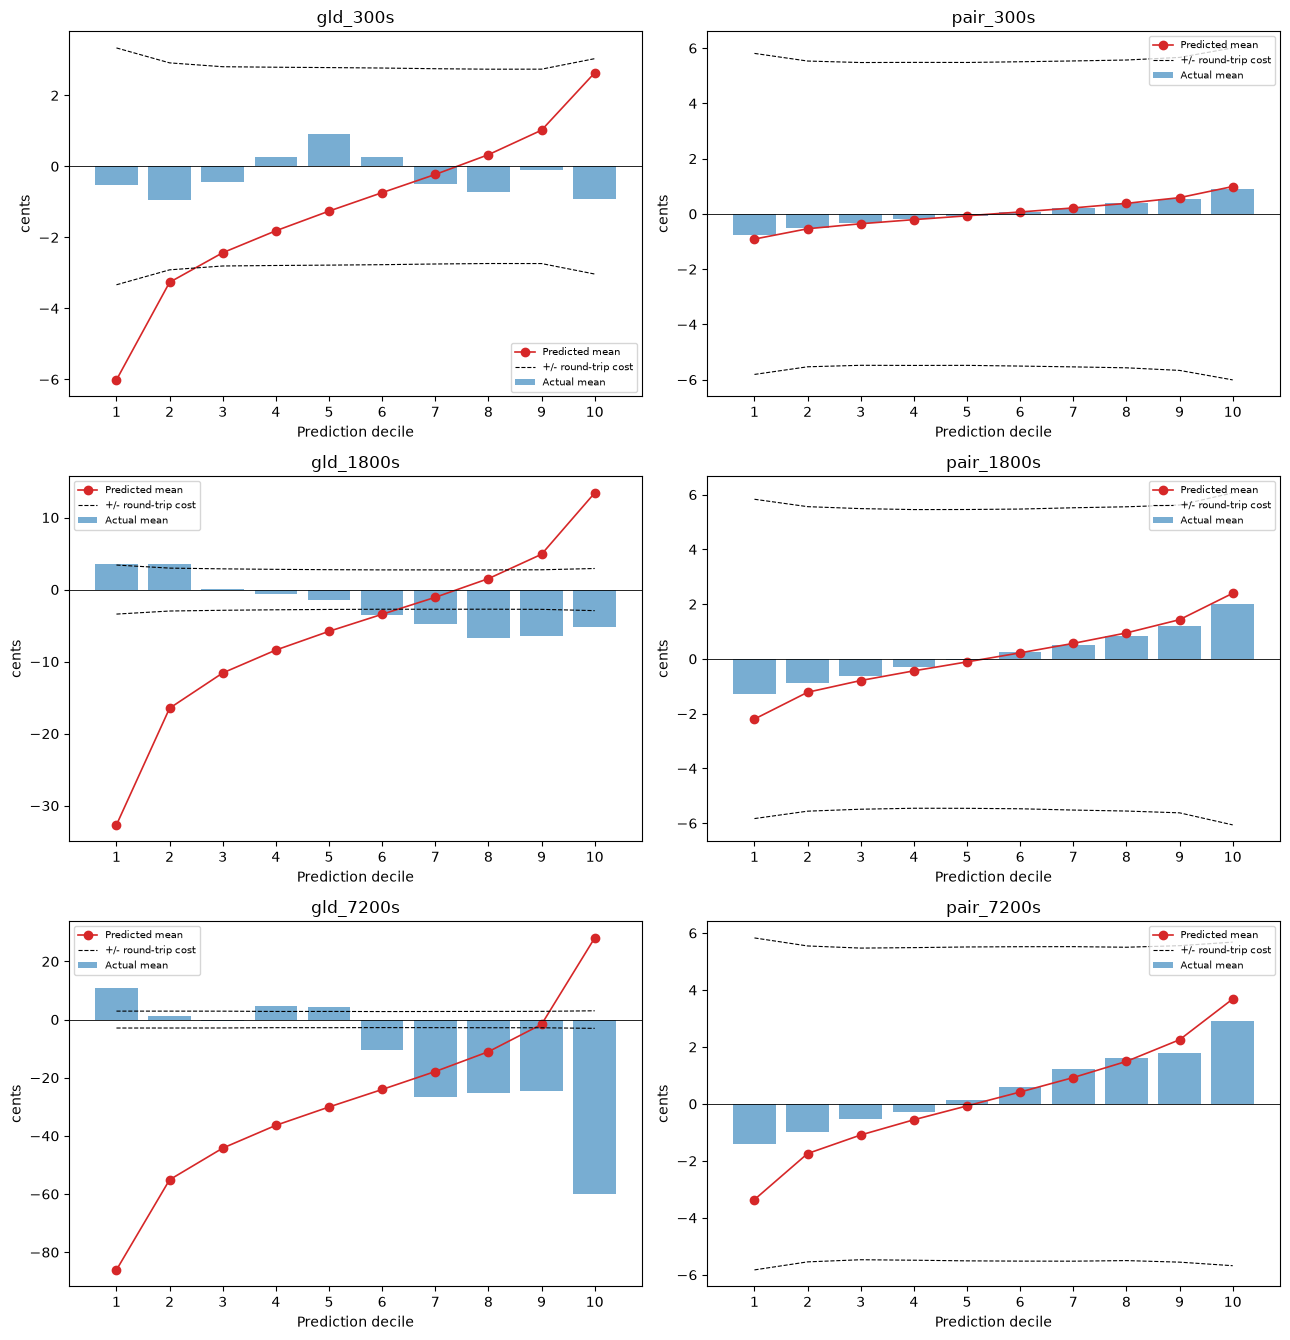

trades  hit_rate  mean_net_c  t_stat  total_net_c
target     cost_mult                                                   
gld_300s   1.0          4272     0.457      -3.025  -6.329   -12923.000
           1.5          3156     0.462      -2.382  -4.174    -7519.000
           2.0          2263     0.475      -1.914  -2.829    -4331.000
           3.0          1105     0.472      -2.240  -2.170    -2475.000
pair_300s  1.0             0       NaN         NaN     NaN          NaN
           1.5             0       NaN         NaN     NaN          NaN
           2.0             0       NaN         NaN     NaN          NaN
           3.0             0       NaN         NaN     NaN          NaN
gld_1800s  1.0           968     0.475      -4.545  -1.906    -4400.000
           1.5           968     0.481      -3.775  -1.576    -3654.000
           2.0           968     0.466      -5.974  -2.487    -5783.000
           3.0           952     0.472      -5.332  -2.275    -5076.000
pair_1800s 1.0            79     0.291      -2.837  -5.264     -224.089
           1.5            10     0.600       1.411   0.848       14.114
           2.0             1       NaN         NaN     NaN          NaN
           3.0             0       NaN         NaN     NaN          NaN
gld_7200s  1.0           176     0.438     -27.517  -2.429    -4843.000
           1.5           176     0.432     -28.057  -2.477    -4938.000
           2.0           176     0.449     -22.261  -1.959    -3918.000
           3.0           176     0.460     -19.250  -1.689    -3388.000
pair_7200s 1.0           119     0.235      -3.124  -6.378     -371.748
           1.5            36     0.306      -3.823  -3.098     -137.645
           2.0            11     0.364      -2.201  -0.752      -24.206
           3.0             0       NaN         NaN     NaN          NaN

In [25]:
COST_MULTS = [1.0, 1.5, 2.0, 3.0]

pred_entry_cost = {
    t: data[("X", "gld_spread_c")] if t.startswith("gld") else data[("X", "gld_spread_c")] + data[("X", "gc_spread_c")]
    for t in targets
}


def non_overlapping(times, h):
    keep, next_ok = [], None
    for t in times:
        if next_ok is None or t >= next_ok:
            keep.append(t)
            next_ok = t + pd.Timedelta(seconds=h + 1)
    return keep


fig, axes = plt.subplots(len(HORIZONS), 2, figsize=(13, 4.5 * len(HORIZONS)))
for ax, t in zip(axes.flat, targets):
    m = preds[t].notna() & data[("y", t)].notna()
    dec = pd.qcut(preds.loc[m, t], 10, labels=False, duplicates="drop")
    g = pd.DataFrame({
        "pred": preds.loc[m, t],
        "actual": data.loc[m, ("y", t)],
        "cost": data.loc[m, ("c", t)],
    }).groupby(dec).mean()
    x = np.arange(len(g))
    ax.bar(x, g["actual"], color="C0", alpha=0.6, label="Actual mean")
    ax.plot(x, g["pred"], color="C3", marker="o", lw=1.2, label="Predicted mean")
    ax.plot(x, g["cost"], color="black", ls="--", lw=0.8, label="+/- round-trip cost")
    ax.plot(x, -g["cost"], color="black", ls="--", lw=0.8)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i + 1) for i in x])
    ax.set_xlabel("Prediction decile")
    ax.set_ylabel("cents")
    ax.set_title(t)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

trade_rows = []
for t in targets:
    h = int(t.split("_")[1][:-1])
    p, y, c, ce = preds[t], data[("y", t)], data[("c", t)], pred_entry_cost[t]
    for k in COST_MULTS:
        cand = p.notna() & y.notna() & (p.abs() > k * ce)
        times = non_overlapping(p.index[cand], h)
        if len(times) < 2:
            trade_rows.append({"target": t, "cost_mult": k, "trades": len(times)})
            continue
        net = np.sign(p.loc[times]) * y.loc[times] - c.loc[times]
        trade_rows.append({
            "target": t,
            "cost_mult": k,
            "trades": len(times),
            "hit_rate": (net > 0).mean(),
            "mean_net_c": net.mean(),
            "t_stat": net.mean() / (net.std(ddof=1) / np.sqrt(len(net))),
            "total_net_c": net.sum(),
        })

pred_trades = pd.DataFrame(trade_rows).set_index(["target", "cost_mult"])
display(pred_trades.round(3))

## D. Results

### 20 SIGNIFICANCE

In [21]:
N_BOOT = 5000
rng = np.random.default_rng(0)

stats = {}
decomp = {}
for name, tr in results.items():
    x = tr["net_c"].to_numpy()
    boot = rng.choice(x, size=(N_BOOT, len(x)), replace=True).mean(axis=1)
    daily = tr.groupby("day")["net_c"].sum().reindex(valid_days, fill_value=0.0).to_numpy()
    day_boot = rng.choice(daily, size=(N_BOOT, len(daily)), replace=True).mean(axis=1)
    stats[name] = {
        "n": len(x),
        "mean_c": x.mean(),
        "sd_c": x.std(ddof=1),
        "t_stat": x.mean() / (x.std(ddof=1) / np.sqrt(len(x))),
        "trade_ci95_lo": np.quantile(boot, 0.025),
        "trade_ci95_hi": np.quantile(boot, 0.975),
        "daily_mean_c": daily.mean(),
        "day_ci95_lo": np.quantile(day_boot, 0.025),
        "day_ci95_hi": np.quantile(day_boot, 0.975),
        "p_daily_mean_le_0": (day_boot <= 0).mean(),
    }
    gold_dir = -tr["gc_net_c"]
    decomp[name] = {
        "spread_capture_c": tr["spread_capture_c"].mean(),
        "pair_net_c": (tr["gld_net_c"] + tr["gc_net_c"]).mean(),
        "gold_direction_c": gold_dir.mean(),
        "gld_leg_net_c": tr["gld_net_c"].mean(),
        "corr(gld_leg, gold_direction)": np.corrcoef(tr["gld_net_c"], gold_dir)[0, 1],
    }

sig_table = pd.DataFrame(stats).T
print(sig_table.round(3), "\n")
print(pd.DataFrame(decomp).T.round(3))

                      n  mean_c    sd_c  t_stat  trade_ci95_lo  trade_ci95_hi  daily_mean_c  day_ci95_lo  day_ci95_hi  p_daily_mean_le_0
touch GLD-only    154.0  -3.026  72.234  -0.520        -14.059          8.625        -4.396      -19.407       11.019              0.714
touch hedged      154.0  -4.668   4.875 -11.885         -5.434         -3.904        -6.782       -8.753       -5.064              1.000
reentry GLD-only   69.0  11.116  76.000   1.215         -6.276         28.581         7.236       -5.425       19.293              0.129
reentry hedged     69.0  -4.769   4.957  -7.992         -5.959         -3.671        -3.105       -4.509       -1.977              1.000 

                  spread_capture_c  pair_net_c  gold_direction_c  gld_leg_net_c  corr(gld_leg, gold_direction)
touch GLD-only               1.928      -4.668             1.642         -3.026                          0.998
touch hedged                 1.928      -4.668             1.642         -3.026            

### 21 SENSITIVITY

min_gap_c: average net per trade (cents)
run    reentry GLD-only  reentry hedged  touch GLD-only  touch hedged
label                                                                
4                -8.440          -4.525          -5.114        -4.383
6                -6.385          -4.461          -5.826        -4.540
8                11.116          -4.769          -3.026        -4.668
10                5.435          -4.531           4.490        -5.039
12              -42.000          -4.165         -24.389        -5.551
16             -145.000          -3.183         -75.200        -7.233
min_gap_c: trades
run    reentry GLD-only  reentry hedged  touch GLD-only  touch hedged
label                                                                
4                 666.0           666.0          1258.0        1258.0
6                 218.0           218.0           385.0         385.0
8                  69.0            69.0           154.0         154.0
10                 23.0        

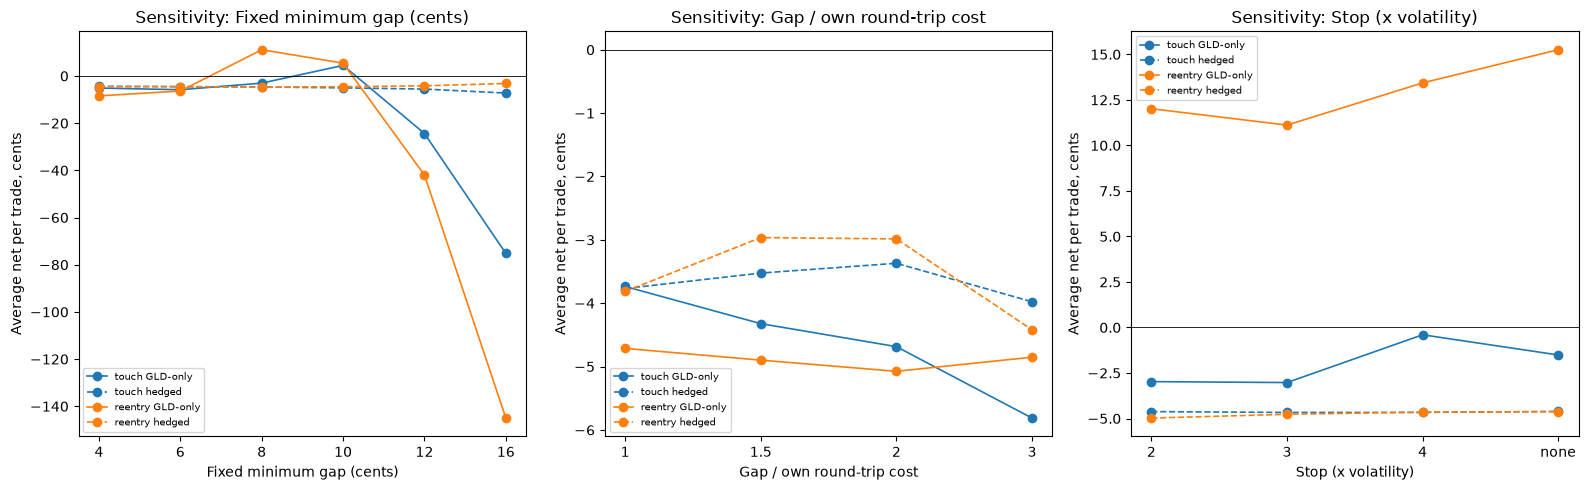

In [22]:
GAP_GRID = [4.0, 6.0, 8.0, 10.0, 12.0, 16.0]
COST_GRID = [1.0, 1.5, 2.0, 3.0]
STOP_GRID = [2.0, 3.0, 4.0, 1e9]
SENS_COLS = ["trades", "avg_spread_capture_c", "avg_cost_c", "avg_net_c", "t_stat", "total_net_c", "daily_sharpe_ann"]


def run_grid(param, values, **fixed):
    rows = []
    for v in values:
        for m in MODES:
            for var in VARIANTS:
                st = summarise(run_backtest(m, var, **{param: v}, **fixed))
                rows.append({"param": param, "value": v, "run": f"{m} {var}", **st[SENS_COLS].to_dict()})
    return pd.DataFrame(rows)


sens = pd.concat([
    run_grid("min_gap_c", GAP_GRID, gap_rule="fixed"),
    run_grid("cost_mult", COST_GRID, gap_rule="cost", cost_basis="own"),
    run_grid("stop_sigma", STOP_GRID),
], ignore_index=True)
sens["label"] = sens["value"].map(lambda v: "none" if v >= 1e9 else f"{v:g}")

for param in sens["param"].unique():
    sub = sens[sens["param"] == param]
    print(f"{param}: average net per trade (cents)")
    print(sub.pivot(index="label", columns="run", values="avg_net_c").reindex(sub["label"].unique()).round(3))
    print(f"{param}: trades")
    print(sub.pivot(index="label", columns="run", values="trades").reindex(sub["label"].unique()), "\n")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titles = {
    "min_gap_c": "Fixed minimum gap (cents)",
    "cost_mult": "Gap / own round-trip cost",
    "stop_sigma": "Stop (x volatility)",
}
for ax, param in zip(axes, ["min_gap_c", "cost_mult", "stop_sigma"]):
    sub = sens[sens["param"] == param]
    labels = list(sub["label"].unique())
    for name in sub["run"].unique():
        m, v = name.split(" ", 1)
        line = sub[sub["run"] == name].set_index("label").reindex(labels)
        ax.plot(labels, line["avg_net_c"], marker="o", lw=1.2, color=f"C{MODES.index(m)}",
                ls="-" if v == "GLD-only" else "--", label=name)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel(titles[param])
    ax.set_ylabel("Average net per trade, cents")
    ax.set_title(f"Sensitivity: {titles[param]}")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 22 LONGER HOLD

Exit rule: target or time
Average net per trade (cents)
run         reentry GLD-only  reentry hedged  touch GLD-only  touch hedged
max_hold_s                                                                
900                   11.116          -4.769          -3.026        -4.668
1800                  11.939          -4.491          -6.295        -4.014
3600                   0.914          -3.969         -12.053        -3.631
7200                  10.490          -3.635          -7.239        -3.215
Average spread capture vs cost (cents)
run         reentry GLD-only capture  reentry hedged capture  touch GLD-only capture  touch hedged capture  reentry GLD-only cost  reentry hedged cost  touch GLD-only cost  touch hedged cost
max_hold_s                                                                                                                                                                                    
900                            2.071                   2.071             

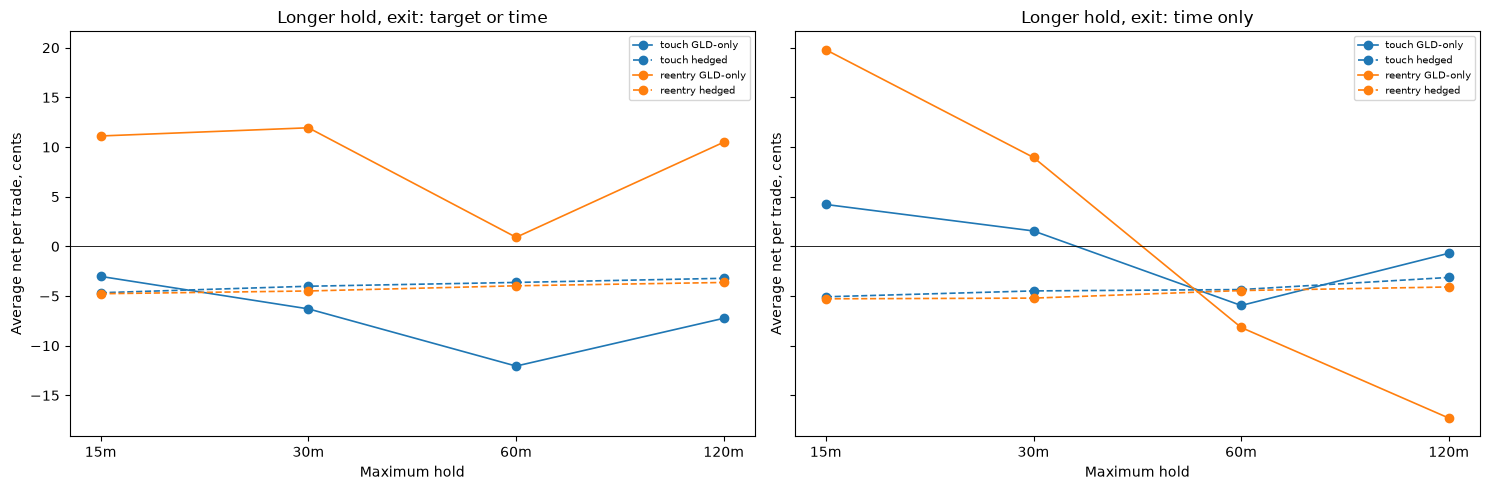

In [23]:
HOLD_GRID = [900, 1800, 3600, 7200]
EXIT_RULES = {"target or time": True, "time only": False}
HOLD_COLS = ["trades", "avg_hold_s", "avg_spread_capture_c", "avg_cost_c", "avg_net_c", "t_stat", "total_net_c", "daily_sharpe_ann"]

exit_at_s = pd.Timedelta(BASE["exit_at"]).total_seconds()
base_last_s = pd.Timedelta(BASE["last_entry"]).total_seconds()

hold_rows = []
hold_results = {}
for h in HOLD_GRID:
    le_s = min(base_last_s, exit_at_s - h)
    le = f"{int(le_s // 3600):02d}:{int(le_s % 3600 // 60):02d}:{int(le_s % 60):02d}"
    for rule, use_t in EXIT_RULES.items():
        for m in MODES:
            for v in VARIANTS:
                tr = run_backtest(m, v, max_hold=h, exit_on_target=use_t, last_entry=le)
                hold_results[(h, rule, f"{m} {v}")] = tr
                st = summarise(tr)
                hold_rows.append({"max_hold_s": h, "last_entry": le, "exit_rule": rule, "run": f"{m} {v}", **st[HOLD_COLS].to_dict()})

hold_tbl = pd.DataFrame(hold_rows)
for rule in EXIT_RULES:
    sub = hold_tbl[hold_tbl["exit_rule"] == rule]
    print(f"Exit rule: {rule}")
    print("Average net per trade (cents)")
    print(sub.pivot(index="max_hold_s", columns="run", values="avg_net_c").round(3))
    print("Average spread capture vs cost (cents)")
    print(sub.pivot(index="max_hold_s", columns="run", values="avg_spread_capture_c").round(3).add_suffix(" capture")
          .join(sub.pivot(index="max_hold_s", columns="run", values="avg_cost_c").round(3).add_suffix(" cost")))
    print("Trades")
    print(sub.pivot(index="max_hold_s", columns="run", values="trades"), "\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, rule in zip(axes, EXIT_RULES):
    sub = hold_tbl[hold_tbl["exit_rule"] == rule]
    for name in sub["run"].unique():
        m, v = name.split(" ", 1)
        line = sub[sub["run"] == name].set_index("max_hold_s")
        ax.plot([f"{x // 60}m" for x in line.index], line["avg_net_c"], marker="o", lw=1.2,
                color=f"C{MODES.index(m)}", ls="-" if v == "GLD-only" else "--", label=name)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel("Maximum hold")
    ax.set_ylabel("Average net per trade, cents")
    ax.set_title(f"Longer hold, exit: {rule}")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 23 RESULTS SUMMARY

In [24]:
sens_by_run = sens.groupby("run")
hold_by_run = hold_tbl.groupby("run")

overview = pd.DataFrame({
    "baseline_trades": summary.loc["trades"],
    "baseline_avg_net_c": summary.loc["avg_net_c"],
    "baseline_t_stat": summary.loc["t_stat"],
    "baseline_total_net_c": summary.loc["total_net_c"],
    "day_ci95_lo": sig_table["day_ci95_lo"],
    "day_ci95_hi": sig_table["day_ci95_hi"],
    "sens_settings": sens_by_run.size(),
    "sens_share_positive": sens_by_run["avg_net_c"].apply(lambda x: (x > 0).mean()),
    "sens_best_avg_net_c": sens_by_run["avg_net_c"].max(),
    "sens_worst_avg_net_c": sens_by_run["avg_net_c"].min(),
    "hold_share_positive": hold_by_run["avg_net_c"].apply(lambda x: (x > 0).mean()),
    "hold_best_avg_net_c": hold_by_run["avg_net_c"].max(),
})
print("Rule-based backtest overview")
print(overview.round(3), "\n")

print("Prediction model fit (out of sample)")
print(pd.DataFrame(fit_rows).T.round(4), "\n")

print("Prediction-based trades")
print(pred_trades.round(3))

Rule-based backtest overview
                  baseline_trades  baseline_avg_net_c  baseline_t_stat  baseline_total_net_c  day_ci95_lo  day_ci95_hi  sens_settings  sens_share_positive  sens_best_avg_net_c  sens_worst_avg_net_c  \
reentry GLD-only             69.0              11.116            1.215               767.000       -5.425       19.293             14                0.429               15.254              -145.000   
reentry hedged               69.0              -4.769           -7.992              -329.078       -4.509       -1.977             14                0.000               -2.965                -4.977   
touch GLD-only              154.0              -3.026           -0.520              -466.000      -19.407       11.019             14                0.071                4.490               -75.200   
touch hedged                154.0              -4.668          -11.885              -718.924       -8.753       -5.064             14                0.000             